# Estimación de RUL en N-CMAPSS (DS02) — ProjectV04

**Trabajo de título:** *Estimación de la vida útil remanente en sistemas de propulsión
aeronáutica mediante arquitecturas híbridas de aprendizaje profundo*
Matías Godoy Rojas — ROL 201821090-0 — Prof. guía: Mauricio Araya L.

Este notebook implementa, por etapas, lo acordado en la **Reunión 05**. El detalle de
cada etapa y sus decisiones está en `Plan_ProjectV04.md`.

| Etapa | Contenido | Estado |
|---|---|---|
| 0 | Infraestructura común con la opción de *pooling*, y reutilización verificada de las corridas de v02 | Completada |
| 1 | Pooling: revisión bibliográfica y experimento con A6-P1 y A6-P2 | Completada: el pooling no se adopta |
| 2 | Validación cruzada y prueba de la variante con pooling (solo si se adopta) | No aplica: el pooling no se adoptó |
| 3 | Regímenes de operación: dimensiones usadas, más grupos y espacio de 18 dimensiones | Completada |
| 4 | Documentación | Completada |

**Punto de partida.** La configuración final de v03 es A6 (CNN + atención), con
normalización global y pérdida asimétrica con α = 2. v04 no repite la ablación, la
elección de α ni la validación cruzada de v03: esas etapas están en `RULv03.ipynb`. Aquí
solo se cargan las corridas necesarias para comparar.

**Relación con ProjectV02 y ProjectV03.** El entrenamiento es exactamente el de v02 y
v03, con early stopping (máximo 30 épocas, paciencia de 5). Como el pipeline es
determinista, v04 **reutiliza las corridas de v02** después de verificar que el código de
este notebook las reproduce exactamente (sección 0.14). Lo único nuevo en el código de
entrenamiento es la opción de agregar capas de *pooling* (sección 0.8), que se usa desde
la etapa 1.

**Cómo re-ejecutar.** Cada entrenamiento se guarda en `results/runs/`. Al volver a
ejecutar el notebook, los entrenamientos ya completos se cargan desde disco en vez de
repetirse.

# Etapa 0 — Infraestructura común

## 0.1 Dependencias

Si falta alguna, descomentar y ejecutar una sola vez:

```python
%pip install h5py scikit-learn torch pandas numpy matplotlib
```

In [1]:
# --- Biblioteca estándar ---
import os          # rutas y creación de carpetas
import glob        # búsqueda de archivos por patrón (para encontrar las corridas de v02)
import shutil      # copia de carpetas (corridas de v02)
import json        # lectura y escritura de configuraciones y resultados
import math        # raíz cuadrada en escalares
import time        # medición de tiempos de entrenamiento
import random      # semilla del generador aleatorio de Python
import hashlib     # hash de la configuración, para identificar corridas
import warnings    # para silenciar advertencias que no aportan

# --- Bibliotecas científicas ---
import h5py                                  # lectura del archivo HDF5 de N-CMAPSS
import numpy as np                           # arreglos numéricos
import pandas as pd                          # tablas de resultados
import torch                                 # tensores y redes neuronales
import torch.nn as nn                        # capas (Conv1d, LSTM, Linear, ...)
from torch.utils.data import TensorDataset, DataLoader   # entrega de datos por lotes
from sklearn.preprocessing import StandardScaler         # estandarización (media 0, desv. 1)

import matplotlib.pyplot as plt              # figuras
import matplotlib.ticker as mticker          # control de las marcas de los ejes

warnings.filterwarnings("ignore", category=UserWarning)

# Las figuras se muestran dentro del notebook
%matplotlib inline

# Se usa GPU si existe; en el equipo de desarrollo solo hay CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | dispositivo activo: {device}")

PyTorch 2.7.1+cpu | dispositivo activo: cpu


## 0.2 Configuración

Todos los hiperparámetros están aquí. El diccionario `HP` reúne los que afectan al
entrenamiento: con él se calcula un *hash* (una huella corta del contenido) que forma
parte del identificador de cada corrida. Si cambia cualquier valor de `HP`, cambia el
hash, y el notebook reentrena en vez de reutilizar resultados obtenidos con otra
configuración.

`SMOKE_TEST = True` ejecuta todo con datos reducidos y dos épocas, en una carpeta de
corridas separada, solo para comprobar que el código corre de principio a fin.

In [2]:
SMOKE_TEST = False

# --- Rutas (relativas a la carpeta del notebook) ---
DATASET_PATH = "D:/Ramos/Memoria_Titulacion_ELO308/Dataset/N-CMAPSS_DS02-006.h5"
OUT_DIR = "results"
RUNS_DIR = os.path.join(OUT_DIR, "runs_smoke" if SMOKE_TEST else "runs")
VERIF_DIR = os.path.join(OUT_DIR, "verificacion_smoke" if SMOKE_TEST else "verificacion")  # sección 0.14
SELECTION_FILE = os.path.join(OUT_DIR, "seleccion.json")
V02_RUNS = "../ProjectV02/results/runs"              # corridas de v02 que se reutilizan
os.makedirs(RUNS_DIR, exist_ok=True)

# --- Datos ---
SAMPLE_STEP = 10       # se toma 1 de cada 10 registros: los datos vienen a 1 Hz -> 1 dato cada 10 s
WINDOW_SIZE = 30       # pasos por ventana: 30 x 10 s = 300 s = 5 minutos de vuelo
STRIDE = 10            # desplazamiento entre ventanas consecutivas (se solapan 20 de 30 pasos)
USE_PWL = True         # recorte lineal por tramos del RUL (ver sección 0.4)

# --- Partición oficial por motor ---
TRAIN_UNITS = [2.0, 5.0, 10.0, 16.0]   # motores de entrenamiento
VAL_UNITS = [18.0, 20.0]               # motores de validación (eligen época y configuración)
# Los motores de prueba (11, 14, 15) son la partición 'test' del archivo HDF5

# --- Zonas de evaluación, en ciclos de RUL restante ---
FINAL_ZONE = 20.0      # zona final: métrica principal (criterio acordado en la Reunión 03)
ZONES = [("Final", 0.0, 20.0), ("Intermedia", 20.0, 40.0), ("Temprana", 40.0, np.inf)]

# --- Modelos (mismos tamaños que v02) ---
CONV_CHANNELS = 32     # filtros de la primera convolución
HIDDEN_SIZE = 64       # dimensión de las características que llegan a la agregación
DROPOUT = 0.2          # fracción de activaciones que se apagan al azar durante el entrenamiento

# --- Entrenamiento ---
SEEDS = [0, 1, 2, 3, 4]
BATCH_SIZE = 256       # ventanas por lote
MAX_EPOCHS = 30        # máximo de épocas; las curvas se grafican siempre en un eje de 1 a 30
PATIENCE = 5           # early stopping: se detiene tras 5 épocas sin mejorar en validación
LR = 1e-3              # tasa de aprendizaje del optimizador Adam
WEIGHT_DECAY = 1e-4    # regularización L2 sobre los pesos

if SMOKE_TEST:
    SEEDS = [0]
    MAX_EPOCHS = 2
    PATIENCE = 2

# Hiperparámetros que definen una corrida: cualquier cambio aquí invalida la caché.
# Son exactamente los de v02, para poder reutilizar sus corridas.
HP = dict(SAMPLE_STEP=SAMPLE_STEP, WINDOW_SIZE=WINDOW_SIZE, STRIDE=STRIDE, USE_PWL=USE_PWL,
          CONV_CHANNELS=CONV_CHANNELS, HIDDEN_SIZE=HIDDEN_SIZE, DROPOUT=DROPOUT,
          BATCH_SIZE=BATCH_SIZE, MAX_EPOCHS=MAX_EPOCHS, PATIENCE=PATIENCE, LR=LR,
          WEIGHT_DECAY=WEIGHT_DECAY, SMOKE_TEST=SMOKE_TEST)
HP_HASH = hashlib.md5(json.dumps(HP, sort_keys=True).encode()).hexdigest()[:8]
V02_HASH = "405955a4"  # hash de configuración de las corridas de v02
if not SMOKE_TEST:
    # Si este assert falla, la configuración difiere de v02 y sus corridas no son reutilizables
    assert HP_HASH == V02_HASH, f"configuración distinta de v02: {HP_HASH} != {V02_HASH}"

# --- Estilo de figuras ---
# Un color fijo por arquitectura, el mismo de v02 (atención = azul, último estado = naranjo)
ARCH_COLORS = {"A5": "#2a78d6", "A3": "#eb6834", "A1": "#1baf7a",
               "A2": "#eda100", "A4": "#e87ba4", "A6": "#008300",
               # Variantes de A6 con pooling (etapa 1): colores nuevos, distintos de A1-A6
               "A6P1": "#4a3aa7", "A6P2": "#e34948"}
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"     # tinta principal, secundaria y tenue
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"   # grilla, ejes y fondo

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
})

print(f"Modo: {'SMOKE TEST' if SMOKE_TEST else 'CORRIDA DEFINITIVA'} | "
      f"hash de configuración: {HP_HASH} | corridas en: {RUNS_DIR}")

Modo: CORRIDA DEFINITIVA | hash de configuración: 405955a4 | corridas en: results\runs


## 0.3 Carga desde HDF5

El archivo trae dos particiones oficiales, `dev` (desarrollo) y `test` (prueba). De
cada una se leen:

- `W`: 4 condiciones de vuelo (altitud, Mach, ángulo del acelerador TRA, temperatura de
  entrada T2).
- `X_s`: 14 sensores físicos.
- `Y`: el RUL de cada registro, en ciclos de vuelo.
- `A`: datos auxiliares: unidad (motor), ciclo de vuelo, clase de vuelo `Fc` e
  indicador de salud `hs` (1 = sano, 0 = degradado).

Se descartan los sensores virtuales `X_v` y los parámetros de salud `T`, porque no se
pueden medir en un motor real. Como el archivo pesa 2,4 GB, se lee una de cada 10 filas
directamente desde el disco, y el resultado se guarda en una caché `.npz`.

In [3]:
def _names(f, key):
    """Devuelve los nombres de las variables guardados en el HDF5 (vienen como bytes)."""
    return [v.decode() if isinstance(v, bytes) else str(v) for v in np.array(f[key]).flatten()]


def load_ncmapss(file_path, sample_step=10, cache_dir=OUT_DIR):
    """Carga las particiones 'dev' y 'test' submuestreadas, usando una caché en disco."""
    cache = os.path.join(cache_dir, f"cache_step{sample_step}.npz")
    meta_file = os.path.join(cache_dir, f"cache_step{sample_step}_vars.json")
    keys = ("features", "rul", "unit", "cycle", "fc", "hs")

    # Si la caché existe y tiene todas las variables, se usa y se evita leer el HDF5
    if os.path.exists(cache) and os.path.exists(meta_file):
        z = np.load(cache)
        if all(f"{s}_{k}" in z for s in ("dev", "test") for k in keys):
            print(f"Cargando desde caché: {cache}")
            with open(meta_file, encoding="utf-8") as fh:
                var_names = json.load(fh)
            return {s: {k: z[f"{s}_{k}"] for k in keys} for s in ("dev", "test")}, var_names

    data = {}
    print(f"Leyendo {file_path} (1 de cada {sample_step} registros)...")
    with h5py.File(file_path, "r") as f:
        var_names = {"W": _names(f, "W_var"), "X_s": _names(f, "X_s_var"), "A": _names(f, "A_var")}
        for split in ("dev", "test"):
            # [::sample_step] lee solo las filas necesarias, sin cargar el archivo completo
            W = np.array(f[f"W_{split}"][::sample_step], dtype=np.float32)
            Xs = np.array(f[f"X_s_{split}"][::sample_step], dtype=np.float32)
            Y = np.array(f[f"Y_{split}"][::sample_step], dtype=np.float32).ravel()
            A = np.array(f[f"A_{split}"][::sample_step], dtype=np.float32)
            data[split] = {
                "features": np.hstack([W, Xs]).astype(np.float32),   # 4 + 14 = 18 columnas
                "rul": Y,
                "unit": A[:, 0], "cycle": A[:, 1], "fc": A[:, 2], "hs": A[:, 3],
            }
            print(f"  {split:4s}: {len(Y):>7d} registros")
    np.savez_compressed(cache, **{f"{s}_{k}": v for s, d in data.items() for k, v in d.items()})
    with open(meta_file, "w", encoding="utf-8") as fh:
        json.dump(var_names, fh, ensure_ascii=False, indent=2)
    return data, var_names


data, var_names = load_ncmapss(DATASET_PATH, SAMPLE_STEP)
dev, test = data["dev"], data["test"]
FEATURE_NAMES = var_names["W"] + var_names["X_s"]   # orden de las 18 columnas de entrada
NUM_FEATURES = len(FEATURE_NAMES)
print(f"Canales de entrada ({NUM_FEATURES}): {FEATURE_NAMES}")

Cargando desde caché: results\cache_step10.npz


Canales de entrada (18): ['alt', 'Mach', 'TRA', 'T2', 'T24', 'T30', 'T48', 'T50', 'P15', 'P2', 'P21', 'P24', 'Ps30', 'P40', 'P50', 'Nf', 'Nc', 'Wf']


## 0.4 Umbral PwL y zonas de evaluación

**Recorte lineal por tramos (PwL).** Mientras el motor está sano, los sensores no
indican cuánto falta para la falla, así que no tiene sentido pedirle al modelo que
distinga 80 de 70 ciclos restantes. El RUL se recorta a un máximo: la mediana del RUL
en el momento en que los motores de entrenamiento pasan de sanos a degradados, según el
indicador `hs` del propio dataset.

In [4]:
# RUL en el instante de transición sano -> degradado de cada motor de entrenamiento:
# es el mayor RUL entre los registros ya degradados (hs == 0) de ese motor
transitions = [float(dev["rul"][(dev["unit"] == u) & (dev["hs"] == 0)].max()) for u in TRAIN_UNITS]
RUL_MAX = float(np.round(np.median(transitions)))
print(f"RUL en la transición sano -> degradado (entrenamiento): {transitions}")
print(f"Umbral PwL: {RUL_MAX:.0f} ciclos")

# Etiquetas recortadas: todo RUL mayor que el umbral se reemplaza por el umbral
rul_dev = np.clip(dev["rul"], 0.0, RUL_MAX) if USE_PWL else dev["rul"].copy()
rul_test = np.clip(test["rul"], 0.0, RUL_MAX) if USE_PWL else test["rul"].copy()

print("\nFracción de registros por zona de evaluación:")
for name, lo, hi in ZONES:
    # La primera zona incluye RUL = 0; las demás excluyen su borde inferior
    fd = np.mean((rul_dev > lo) & (rul_dev <= hi)) if lo > 0 else np.mean(rul_dev <= hi)
    print(f"   {name:<11} ({lo:>4.0f}, {hi:>4.0f}]  dev {100 * fd:5.1f} %")

RUL en la transición sano -> degradado (entrenamiento): [58.0, 72.0, 65.0, 47.0]
Umbral PwL: 62 ciclos

Fracción de registros por zona de evaluación:
   Final       (   0,   20]  dev  27.7 %
   Intermedia  (  20,   40]  dev  27.2 %
   Temprana    (  40,  inf]  dev  45.1 %


## 0.5 Particiones por motor

Ningún motor aparece en dos conjuntos: en operación, el modelo se enfrenta a motores
que nunca vio. Una partición se describe con sus motores de entrenamiento, validación y
evaluación. La partición `oficial` evalúa sobre el conjunto de prueba del HDF5. Si la
etapa 1 adopta el pooling, la etapa 2 agregará una partición por cada fold de la
validación cruzada.

In [5]:
SPLITS = {"oficial": {"name": "oficial", "train": TRAIN_UNITS, "val": VAL_UNITS, "eval": "test"}}

# Comprobaciones de que no hay motores compartidos entre conjuntos
assert not np.any(np.isin(TRAIN_UNITS, VAL_UNITS))
assert len(np.intersect1d(np.unique(dev["unit"]), np.unique(test["unit"]))) == 0

_n_tr = np.isin(dev["unit"], TRAIN_UNITS).sum()
_n_va = np.isin(dev["unit"], VAL_UNITS).sum()
_n_te = len(test["unit"])
_n = _n_tr + _n_va + _n_te
print("Partición oficial (registros submuestreados):")
print(f"   Entrenamiento  motores  2, 5, 10, 16 : {_n_tr:>7,d}  ({100 * _n_tr / _n:4.1f} %)")
print(f"   Validación     motores 18, 20        : {_n_va:>7,d}  ({100 * _n_va / _n:4.1f} %)")
print(f"   Prueba         motores 11, 14, 15    : {_n_te:>7,d}  ({100 * _n_te / _n:4.1f} %)")

Partición oficial (registros submuestreados):
   Entrenamiento  motores  2, 5, 10, 16 : 360,457  (55.3 %)
   Validación     motores 18, 20        : 165,888  (25.5 %)
   Prueba         motores 11, 14, 15    : 125,375  (19.2 %)


## 0.6 Normalización global sin fuga de información

Cada uno de los 18 canales se estandariza (se le resta su media y se divide por su
desviación estándar). Las medias y desviaciones se calculan **solo con los motores de
entrenamiento**; validación y prueba se transforman con esos mismos valores. Si se
calcularan con todos los datos, información de los motores de evaluación se filtraría
al entrenamiento.

La normalización global quedó fija desde v03. Los regímenes de operación de la etapa 3
no cambian la normalización del modelo: son solo análisis.

In [6]:
def _fit_global(d, train_mask):
    """Ajusta la estandarización con los registros de entrenamiento y devuelve la transformación."""
    scaler = StandardScaler().fit(d["features"][train_mask])
    return lambda dd: scaler.transform(dd["features"]).astype(np.float32)


NORMALIZERS = {"global": _fit_global}   # nombre -> función que ajusta y devuelve la transformación
NORM_TAGS = {"global": "global"}        # etiqueta de cada normalización en el identificador de corrida


def fit_normalizer(method, d, train_mask):
    """Devuelve la transformación del método pedido, ajustada solo con `train_mask`."""
    return NORMALIZERS[method](d, train_mask)

## 0.7 Ventaneo y construcción de tensores

El modelo no recibe registros sueltos sino **ventanas**: 30 registros consecutivos de un
mismo vuelo, es decir, 5 minutos. La etiqueta de cada ventana es el RUL de su último
registro. Las ventanas nunca cruzan de un vuelo al siguiente, porque mezclarían el
aterrizaje de uno con el despegue del otro.

Las posiciones de las ventanas no dependen de la normalización, así que se calculan una
sola vez. `build_tensors` aplica la normalización y arma tres conjuntos, cada uno con:

- `X`: forma `(N, 30, 18)` — N ventanas, 30 pasos de tiempo, 18 canales.
- `y`: forma `(N,)` — el RUL de cada ventana.
- `meta`: forma `(N, 2)` — motor y ciclo de vuelo de cada ventana.

In [7]:
def _window_starts(d):
    """Calcula dónde empieza cada ventana válida, sin cruzar fronteras de (motor, ciclo)."""
    key = np.stack([d["unit"], d["cycle"]], axis=1)
    # Hay un cambio de vuelo donde el par (motor, ciclo) difiere del registro anterior
    change = np.any(np.diff(key, axis=0) != 0, axis=1)
    bounds = np.concatenate([[0], np.where(change)[0] + 1, [len(d["unit"])]])
    # Dentro de cada vuelo [s, e) caben (e - s - 30) // 10 + 1 ventanas
    starts = [s + np.arange((e - s - WINDOW_SIZE) // STRIDE + 1) * STRIDE
              for s, e in zip(bounds[:-1], bounds[1:]) if e - s >= WINDOW_SIZE]
    starts = np.concatenate(starts)
    last = starts + WINDOW_SIZE - 1                 # índice del último registro de cada ventana
    return starts, d["unit"][last], d["cycle"][last]


WINDOWS = {"dev": _window_starts(dev), "test": _window_starts(test)}
_RUL = {"dev": rul_dev, "test": rul_test}


def _gather(feats, source, units=None):
    """Arma (X, y, meta) con las ventanas de `source` que pertenecen a los motores `units`."""
    starts, w_unit, w_cycle = WINDOWS[source]
    m = np.ones(len(starts), bool) if units is None else np.isin(w_unit, units)
    st = starts[m]
    # Matriz de índices (N, 30): fila i = posiciones de los 30 registros de la ventana i
    idx = st[:, None] + np.arange(WINDOW_SIZE)[None, :]
    X = feats[idx].astype(np.float32)               # (N, 30, 18)
    y = _RUL[source][st + WINDOW_SIZE - 1].astype(np.float32)
    meta = np.stack([w_unit[m], w_cycle[m]], axis=1)
    return X, y, meta


_TENSORS = {}   # memoria: (normalización, partición) -> tensores ya construidos


def build_tensors(norm, split_name):
    """Devuelve {'train', 'val', 'eval'} -> (X, y, meta) para una normalización y partición."""
    key = (norm, split_name)
    if key in _TENSORS:
        return _TENSORS[key]
    sp = SPLITS[split_name]
    # La normalización se ajusta solo con los motores de entrenamiento de esta partición
    transform = fit_normalizer(norm, dev, np.isin(dev["unit"], sp["train"]))
    dev_n = transform(dev)
    out = {"train": _gather(dev_n, "dev", sp["train"]), "val": _gather(dev_n, "dev", sp["val"])}
    # Evaluación: el conjunto de prueba oficial, o un motor de dev en la validación cruzada
    out["eval"] = (_gather(transform(test), "test") if sp["eval"] == "test"
                   else _gather(dev_n, "dev", sp["eval"]))
    if SMOKE_TEST:
        # Submuestra para que la prueba rápida tome segundos
        rng = np.random.default_rng(0)
        for part, n in (("train", 4000), ("val", 2000)):
            X, y, meta = out[part]
            sel = rng.choice(len(X), size=min(n, len(X)), replace=False)
            out[part] = (X[sel], y[sel], meta[sel])
    # Comprobación: ningún motor de entrenamiento aparece en validación ni en evaluación
    for a, b in (("train", "val"), ("train", "eval")):
        assert not np.intersect1d(np.unique(out[a][2][:, 0]), np.unique(out[b][2][:, 0])).size
    _TENSORS[key] = out
    return out


_T = build_tensors("global", "oficial")
for part in ("train", "val", "eval"):
    X, y, _ = _T[part]
    print(f"{part:<6}: X = {str(X.shape):>18s} | RUL medio = {y.mean():5.1f}")
print("OK: sin motores compartidos entre entrenamiento, validación y evaluación.")

train : X =    (35287, 30, 18) | RUL medio =  37.1
val   : X =    (16251, 30, 18) | RUL medio =  33.3
eval  : X =    (12047, 30, 18) | RUL medio =  31.0
OK: sin motores compartidos entre entrenamiento, validación y evaluación.


## 0.8 Catálogo de arquitecturas

Son las seis arquitecturas de v02 y v03, más dos variantes de A6 con *pooling* que se
estudian en la etapa 1. Todas reciben ventanas de forma `(B, 30, 18)`, donde **B** es el
número de ventanas del lote, **30** los pasos de tiempo y **18** los canales. Todas
terminan en el mismo cabezal de regresión.

| Id | Arquitectura | Extractor | Agregación temporal | Inspirada en |
|---|---|---|---|---|
| A1 | 1D-CNN | Conv 18→32 canales, Conv 32→64 canales | promedio | Sateesh Babu et al. (2016); Li, Ding y Sun (2018) |
| A2 | LSTM | LSTM 18→64 | último estado | Zheng et al. (2017); Wu et al. (2018) |
| A3 | CNN + LSTM | Conv 18→32 canales, LSTM 32→64 | último estado | — |
| A4 | LSTM + atención | LSTM 18→64 | atención | de Oliveira da Costa et al. (2019) |
| A5 | CNN + LSTM + atención | Conv 18→32 canales, LSTM 32→64 | atención | Li et al. (2022) |
| A6 | CNN + atención | Conv 18→32 canales, Conv 32→64 canales | atención | — |
| A6-P1 | A6 con pooling tras la 1.ª convolución | Conv 18→32, MaxPool, Conv 32→64 | atención | — |
| A6-P2 | A6 con pooling tras cada convolución | Conv 18→32, MaxPool, Conv 32→64, MaxPool | atención | — |

**Pooling (nuevo en v04).** `MaxPool1d(2)` recorre el eje temporal en tramos de 2 pasos
sin solaparse y deja, para cada canal, el mayor de los dos valores. La longitud temporal
se reduce a la mitad, redondeando hacia abajo: 30 → 15 y 15 → 7 (el paso 15 queda fuera
del segundo pooling, porque no completa un tramo de 2). Los canales no cambian. El
pooling no tiene parámetros que entrenar, así que A6, A6-P1 y A6-P2 tienen exactamente el
mismo número de parámetros; lo único que cambia es cuántos pasos llegan a la atención:

| Id | Forma antes de la atención |
|---|---|
| A6 | (B, 30, 64) |
| A6-P1 | (B, 15, 64) |
| A6-P2 | (B, 7, 64) |

En el código, los identificadores son `A6P1` y `A6P2` (sin guion), porque forman parte
del nombre de la carpeta de cada corrida.

**Sobre "32 → 64" en A1 y A6.** Son canales (filtros), no tiempo. Con `kernel_size=3`,
`padding=1` y paso 1, la longitud de salida de una convolución es
$(30 + 2 \cdot 1 - 3)/1 + 1 = 30$: la dimensión temporal se mantiene en 30 en toda la
red. Solo cambia cuántas características se calculan en cada paso.

**Agregación temporal.** Las capas anteriores producen 64 características en cada uno de
los T pasos (T = 30 sin pooling), forma `(B, T, 64)`. La agregación las resume en un solo
vector de 64 por ventana, forma `(B, 64)`:

- **Último estado:** se toma el último paso y se descartan los demás.
- **Promedio temporal:** se promedian los T pasos, todos con el mismo peso (1/T).
- **Atención:** se promedian los T pasos con pesos aprendidos (clase `TemporalAttention`
  y guía de estudio de v03).

**Limitación conocida.** Los pares A1–A6, A2–A4 y A3–A5 difieren solo en la agregación.
Entre extractores la comparación no es estricta: A1 y A6 tienen una convolución más que
A3 y A5, y la agregación sin atención es el promedio en A1 y el último estado en A2 y A3.

In [8]:
class TemporalAttention(nn.Module):
    """
    Atención aditiva (Bahdanau et al., 2015) sobre la dimensión temporal.

    Para cada paso t calcula un puntaje e_t = v · tanh(W h_t + b), convierte los T
    puntajes en pesos que suman 1 con softmax y devuelve el promedio ponderado de los h_t.
    Funciona con cualquier número de pasos T: 30 sin pooling, 15 en A6-P1 y 7 en A6-P2.
    """

    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, hidden_dim)       # W y b: proyección de cada paso
        self.v = nn.Linear(hidden_dim, 1, bias=False)       # v: reduce cada paso a un puntaje

    def forward(self, h):                                   # h: (B, T, H), p. ej. (B, 30, 64)
        scores = self.v(torch.tanh(self.attn(h)))           # (B, T, 1): un puntaje por paso
        weights = torch.softmax(scores, dim=1)              # (B, T, 1): pesos que suman 1 en t
        context = torch.sum(weights * h, dim=1)             # (B, 64): promedio ponderado
        return context, weights.squeeze(-1)                 # pesos (B, T) para interpretarlos


class RULNet(nn.Module):
    """
    Construye todas las arquitecturas del catálogo a partir de cuatro opciones:
    use_cnn (hay convolución), use_lstm (hay LSTM), aggregation ('last', 'mean',
    'attention') y pool ('none', 'first', 'each'):
      - 'none':  sin pooling (A1-A6, igual que en v02 y v03).
      - 'first': MaxPool1d(2) solo tras la primera convolución (A6-P1).
      - 'each':  MaxPool1d(2) tras cada convolución (A6-P2).
    """

    def __init__(self, num_features, use_cnn, use_lstm, aggregation, pool="none",
                 conv_channels=CONV_CHANNELS, hidden=HIDDEN_SIZE, dropout=DROPOUT):
        super().__init__()
        assert use_cnn or use_lstm
        assert aggregation in ("last", "mean", "attention")
        assert pool in ("none", "first", "each")
        # El pooling actúa sobre la salida de las convoluciones: requiere CNN, y 'each'
        # requiere además la segunda convolución, que solo existe sin LSTM (A1, A6)
        assert pool == "none" or use_cnn
        assert pool != "each" or not use_lstm
        self.use_cnn, self.use_lstm, self.aggregation = use_cnn, use_lstm, aggregation
        self.pool = pool

        # IMPORTANTE: el orden en que se crean las capas determina cómo se consumen los
        # números aleatorios al inicializarlas. Se mantiene el mismo orden que en v01 y
        # v02 para que, con la misma semilla, A3 y A5 partan de pesos idénticos.
        if use_cnn:
            # Primera convolución: 18 canales de entrada -> 32 filtros, ventana de 3 pasos
            self.conv = nn.Conv1d(num_features, conv_channels, kernel_size=3, padding=1)
            self.bn = nn.BatchNorm1d(conv_channels)          # normaliza cada filtro en el lote
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        if use_cnn and not use_lstm:
            # CNN sin LSTM (A1, A6): segunda convolución, 32 -> 64 canales, para llegar a
            # la dimensión 64 que esperan la atención y el cabezal
            self.conv2 = nn.Conv1d(conv_channels, hidden, kernel_size=3, padding=1)
            self.bn2 = nn.BatchNorm1d(hidden)
        if use_lstm:
            # LSTM con 64 unidades; su entrada es 32 si viene de la CNN o 18 si va sola
            self.lstm = nn.LSTM(conv_channels if use_cnn else num_features, hidden,
                                batch_first=True)
        self.attention = TemporalAttention(hidden) if aggregation == "attention" else None
        # Cabezal de regresión: 64 -> 32 -> 1 (el RUL estimado)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))
        # Pooling (nuevo en v04). Se crea al final y no tiene parámetros: no consume números
        # aleatorios, así que no altera la inicialización de las capas anteriores. Con
        # pool='none' la red es idéntica a la de v02 y v03 (lo verifica la sección 0.14).
        # kernel_size=2 y paso 2 (el paso por defecto es igual al tamaño de la ventana)
        self.maxpool = nn.MaxPool1d(kernel_size=2) if pool != "none" else None

    def temporal_features(self, x):
        """Características por paso de tiempo, antes de la agregación: (B, T, 64)."""
        h = x                                               # x: (B, 30, 18)
        if self.use_cnn:
            # Conv1d espera (B, canales, tiempo): se intercambian las dos últimas dimensiones
            z = self.relu(self.bn(self.conv(x.permute(0, 2, 1))))   # (B, 32, 30)
            if self.pool in ("first", "each"):
                z = self.maxpool(z)                         # (B, 32, 15): mitad de los pasos
            z = self.dropout(z)
            if not self.use_lstm:
                z = self.relu(self.bn2(self.conv2(z)))      # (B, 64, T): T = 30 o 15
                if self.pool == "each":
                    z = self.maxpool(z)                     # (B, 64, 7): 15 // 2 = 7 pasos
            h = z.permute(0, 2, 1)                          # de vuelta a (B, T, canales)
        if self.use_lstm:
            h, _ = self.lstm(h)                             # (B, 30, 64): una salida por paso
            if not self.use_cnn:
                h = self.dropout(h)                         # en A2 y A4 el dropout va aquí
        return h

    def forward(self, x):                                   # x: (B, 30, 18)
        h = self.temporal_features(x)                       # (B, T, 64)
        weights = None                                      # solo la atención produce pesos
        if self.aggregation == "attention":
            feat, weights = self.attention(h)               # promedio con pesos aprendidos
        elif self.aggregation == "mean":
            feat = h.mean(dim=1)                            # promedio temporal: peso 1/T a cada paso
        else:
            feat = h[:, -1, :]                              # último estado: solo el último paso
        return self.head(feat), weights                     # RUL (B, 1) y pesos (B, T) o None


# Catálogo: cada arquitectura queda definida por las tres opciones de RULNet
ARCHS = {
    "A1": dict(name="1D-CNN", use_cnn=True, use_lstm=False, aggregation="mean",
               ref="Sateesh Babu et al. (2016); Li, Ding y Sun (2018)"),
    "A2": dict(name="LSTM", use_cnn=False, use_lstm=True, aggregation="last",
               ref="Zheng et al. (2017); Wu et al. (2018)"),
    "A3": dict(name="CNN + LSTM", use_cnn=True, use_lstm=True, aggregation="last",
               ref="— (referencia por definir)"),
    "A4": dict(name="LSTM + atención", use_cnn=False, use_lstm=True, aggregation="attention",
               ref="de Oliveira da Costa et al. (2019)"),
    "A5": dict(name="CNN + LSTM + atención", use_cnn=True, use_lstm=True, aggregation="attention",
               ref="Li et al. (2022)"),
    "A6": dict(name="CNN + atención", use_cnn=True, use_lstm=False, aggregation="attention",
               ref="—"),
    # Variantes con pooling (etapa 1): misma A6, solo cambia la opción pool
    "A6P1": dict(name="CNN + atención, pooling tras la 1.ª conv.", use_cnn=True, use_lstm=False,
                 aggregation="attention", pool="first", ref="—"),
    "A6P2": dict(name="CNN + atención, pooling tras cada conv.", use_cnn=True, use_lstm=False,
                 aggregation="attention", pool="each", ref="—"),
}
# Etiquetas para tablas y figuras; los identificadores A6P1 y A6P2 se muestran con guion
ARCH_IDS = {k: k.replace("A6P", "A6-P") for k in ARCHS}
ARCH_LABELS = {k: f"{ARCH_IDS[k]} · {a['name']}" for k, a in ARCHS.items()}


def make_model(arch):
    """Crea una red nueva (pesos aleatorios) de la arquitectura indicada."""
    a = ARCHS[arch]
    # Las arquitecturas sin la clave 'pool' (A1-A6) se crean sin pooling
    return RULNet(NUM_FEATURES, a["use_cnn"], a["use_lstm"], a["aggregation"],
                  pool=a.get("pool", "none"))


def count_params(model):
    """Número de parámetros que el entrenamiento ajusta."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Comprobación: cada arquitectura procesa un lote de prueba y entrega la forma esperada.
# La columna "Antes de la agregación" muestra la forma del tensor que llega a la atención,
# al promedio o al último estado: con pooling, el número de pasos baja de 30 a 15 o a 7.
_x = torch.randn(4, WINDOW_SIZE, NUM_FEATURES)
rows = []
for k, a in ARCHS.items():
    m = make_model(k).eval()
    out, w = m(_x)
    h = m.temporal_features(_x)
    assert out.shape == (4, 1) and (w is None) == (a["aggregation"] != "attention")
    if w is not None:
        assert w.shape == h.shape[:2]                   # un peso de atención por paso
    rows.append({"Id": ARCH_IDS[k], "Arquitectura": a["name"], "Agregación": a["aggregation"],
                 "Antes de la agregación": "(B, {}, {})".format(*h.shape[1:]),
                 "Parámetros": f"{count_params(m):,}".replace(",", "."), "Inspirada en": a["ref"]})
arch_table = pd.DataFrame(rows)
print(arch_table.to_string(index=False))

# El pooling no tiene parámetros: las tres variantes de A6 deben tener el mismo tamaño
assert count_params(make_model("A6")) == count_params(make_model("A6P1")) == count_params(make_model("A6P2"))
# Con pool='none', la red de cada semilla debe partir de los mismos pesos que en v02 y
# v03. Se comprueba aquí con A6: crear la red con y sin el argumento pool da pesos iguales.
torch.manual_seed(0)
_w_new = make_model("A6").state_dict()
torch.manual_seed(0)
_a = ARCHS["A6"]
_w_old = RULNet(NUM_FEATURES, _a["use_cnn"], _a["use_lstm"], _a["aggregation"]).state_dict()
assert all(torch.equal(_w_new[k], _w_old[k]) for k in _w_old)
# Las variantes con pooling también parten de los mismos pesos que A6 con la misma semilla
torch.manual_seed(0)
_w_p2 = make_model("A6P2").state_dict()
assert all(torch.equal(_w_new[k], _w_p2[k]) for k in _w_new)
print("\nOK: A6, A6-P1 y A6-P2 tienen los mismos parámetros y, con la misma semilla, "
      "los mismos pesos iniciales.")

   Id                              Arquitectura Agregación Antes de la agregación Parámetros                                      Inspirada en
   A1                                    1D-CNN       mean            (B, 30, 64)     10.273 Sateesh Babu et al. (2016); Li, Ding y Sun (2018)
   A2                                      LSTM       last            (B, 30, 64)     23.617             Zheng et al. (2017); Wu et al. (2018)
   A3                                CNN + LSTM       last            (B, 30, 64)     29.025                        — (referencia por definir)
   A4                           LSTM + atención  attention            (B, 30, 64)     27.841                de Oliveira da Costa et al. (2019)
   A5                     CNN + LSTM + atención  attention            (B, 30, 64)     33.249                                  Li et al. (2022)
   A6                            CNN + atención  attention            (B, 30, 64)     14.497                                                 —

## 0.9 Función de pérdida

$\mathcal{L}_\alpha = \frac{1}{N}\sum_i w(d_i)\,d_i^2$, con $d = \hat{y} - y$ y
$w = \alpha$ si $d > 0$ (sobreestimación) o $w = 1$ si no. Con $\alpha = 1$ es
exactamente el error cuadrático medio (MSE), que se usa en la etapa 1. La etapa 2 prueba
$\alpha > 1$.

Es la pérdida de la **regresión por expectiles** (Newey y Powell, 1987): el modelo que la
minimiza no estima la media del RUL sino su expectil de nivel $\tau = 1/(1+\alpha)$, una
estimación conservadora. La referencia completa se verifica en la etapa 2.

In [9]:
class AsymmetricMSELoss(nn.Module):
    """Error cuadrático que penaliza alpha veces más la sobreestimación (y_pred > y)."""

    def __init__(self, alpha=1.0):
        super().__init__()
        assert alpha >= 1.0, "alpha < 1 penalizaría más la subestimación"
        self.alpha = float(alpha)

    def forward(self, pred, target):
        d = pred - target                                   # error con signo
        # Peso = alpha donde se sobreestima, 1 donde no. (d > 0) vale 1 o 0
        w = 1.0 + (self.alpha - 1.0) * (d > 0).float()
        return torch.mean(w * d ** 2)


def asym_rmse(y_true, y_pred, alpha):
    """Versión NumPy de la raíz de L_alpha; con alpha = 1 es el RMSE."""
    d = np.asarray(y_pred).ravel() - np.asarray(y_true).ravel()
    return float(np.sqrt(np.mean((1.0 + (alpha - 1.0) * (d > 0)) * d ** 2)))


# Comprobaciones: con alpha = 1 coincide con el MSE de PyTorch; con alpha = 4 sobreestimar
# 3 ciclos cuesta 4 veces lo mismo que subestimar 3 ciclos
_p, _t = torch.randn(1000, 1) * 10, torch.randn(1000, 1) * 10
assert torch.allclose(AsymmetricMSELoss(1.0)(_p, _t), nn.MSELoss()(_p, _t))
_z = torch.zeros(1, 1)
assert torch.isclose(AsymmetricMSELoss(4.0)(_z + 3, _z), 4 * AsymmetricMSELoss(4.0)(_z - 3, _z))
print("OK: L_alpha con alpha = 1 coincide con el MSE; con alpha = 4 sobreestimar cuesta 4 veces más.")

OK: L_alpha con alpha = 1 coincide con el MSE; con alpha = 4 sobreestimar cuesta 4 veces más.


## 0.10 Métricas

La **zona final (RUL ≤ 20 ciclos)** es la métrica principal: lo que importa es acertar
cuando el fallo está cerca. Además se reportan métricas globales, por zona y por motor.

**Score NASA** (Saxena et al., 2008): por cada predicción suma `exp(-d/13) - 1` si
subestima (`d < 0`) o `exp(d/10) - 1` si sobreestima (`d ≥ 0`). Como 10 < 13, crece más
rápido con la sobreestimación. Se reporta como promedio por muestra.

In [10]:
def rmse(y, p):
    """Raíz del error cuadrático medio; NaN si no hay muestras."""
    y, p = np.asarray(y).ravel(), np.asarray(p).ravel()
    return float(np.sqrt(np.mean((p - y) ** 2))) if len(y) else np.nan


def nasa_score(y, p):
    """Score NASA promedio por muestra (menor es mejor)."""
    d = np.asarray(p).ravel() - np.asarray(y).ravel()
    if not len(d):
        return np.nan
    return float(np.mean(np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)))


def _zone_mask(y, lo, hi):
    """Selecciona las muestras cuyo RUL real cae en la zona (lo, hi]."""
    return (y > lo) & (y <= hi) if lo > 0 else (y <= hi)


def compute_metrics(y, p, meta=None):
    """Todas las métricas de una corrida sobre un conjunto (y real, p predicho)."""
    y, p = np.asarray(y).ravel(), np.asarray(p).ravel()
    d = p - y                       # error con signo: positivo = sobreestima
    fin = y <= FINAL_ZONE           # muestras de la zona final
    out = {
        "RMSE final": rmse(y[fin], p[fin]),
        "Sobreest. media final": float(np.mean(np.clip(d[fin], 0, None))),   # solo errores > 0
        "% sobreest. final": float(100 * np.mean(d[fin] > 0)),
        "Score NASA final": nasa_score(y[fin], p[fin]),
        "RMSE": rmse(y, p),
        "MAE": float(np.mean(np.abs(d))),
        "Score NASA": nasa_score(y, p),
        "Sesgo": float(np.mean(d)),
        "% sobreest.": float(100 * np.mean(d > 0)),
    }
    for name, lo, hi in ZONES[1:]:
        m = _zone_mask(y, lo, hi)
        out[f"RMSE {name.lower()}"] = rmse(y[m], p[m])
    if meta is not None:
        for u in np.unique(meta[:, 0]):        # métricas por motor
            m = meta[:, 0] == u
            out[f"RMSE u{int(u)}"] = rmse(y[m], p[m])
            out[f"RMSE final u{int(u)}"] = rmse(y[m & fin], p[m & fin])
    return out


MAIN_METRICS = ["RMSE final", "Sobreest. media final", "Score NASA final", "RMSE", "Sesgo"]

## 0.11 Entrenamiento reanudable con early stopping

Cada corrida se identifica por arquitectura, normalización, α, semilla, partición y el
hash de configuración, y se guarda en `results/runs/<id>/` con:

- `state.pt`: los pesos de la mejor época.
- `run.json`: el historial época a época y datos de la corrida.
- `preds.npz`: las predicciones sobre validación y sobre evaluación.

Si la carpeta ya existe, la corrida se carga en vez de repetirse.

**Early stopping:** después de cada época se mide el criterio de validación
($\sqrt{\mathcal{L}_\alpha}$; con $\alpha = 1$ es el RMSE). Si es el mejor hasta ese
momento, se guarda una copia de los pesos. Si pasan 5 épocas seguidas sin mejorar, el
entrenamiento se detiene, con un máximo de 30 épocas. Al terminar, el modelo se queda con
los pesos de la mejor época. Por eso cada corrida entrena un número distinto de épocas,
y las curvas de aprendizaje se grafican siempre en un eje común de 1 a 30 para poder
compararlas visualmente.

**Disciplina de evaluación:** las predicciones sobre el conjunto de evaluación se
guardan, pero ningún criterio de selección las lee. En v04, las predicciones sobre el
conjunto de prueba oficial solo se consultan en la etapa 2, y solo si la etapa 1 adopta
el pooling.

In [11]:
def set_seed(seed):
    """Fija todas las fuentes de aleatoriedad para que la corrida sea reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def _loader(X, y, shuffle=False, generator=None):
    """Envuelve (X, y) en un DataLoader que entrega lotes de BATCH_SIZE ventanas."""
    ds = TensorDataset(torch.from_numpy(np.ascontiguousarray(X)),
                       torch.from_numpy(np.ascontiguousarray(y)).unsqueeze(1))
    # En entrenamiento se baraja y se descarta el último lote incompleto (drop_last)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0,
                      generator=generator, drop_last=shuffle)


@torch.no_grad()   # en predicción no se calculan gradientes: más rápido y menos memoria
def predict(model, X, collect_weights=False):
    """Predice el RUL de todas las ventanas de X; opcionalmente devuelve los pesos de atención."""
    model.eval()   # desactiva el dropout y usa las estadísticas fijas de BatchNorm
    preds, weights = [], []
    for X_b, _ in _loader(X, np.zeros(len(X), np.float32)):
        out, w = model(X_b.to(device))
        preds.append(out.cpu().numpy().ravel())
        if collect_weights and w is not None:
            weights.append(w.cpu().numpy())
    return np.concatenate(preds), (np.concatenate(weights) if weights else None)


def run_id(arch, norm, alpha, seed, split):
    """Identificador único de una corrida (nombre de su carpeta)."""
    return f"{arch}_{NORM_TAGS.get(norm, norm)}_a{alpha:g}_s{seed}_{split}_{HP_HASH}"


def run(arch, norm="global", alpha=1.0, seed=0, split="oficial", base_dir=None):
    """
    Entrena (o carga desde disco) una corrida y devuelve su registro.
    `base_dir` permite guardarla en otra carpeta; la verificación 0.14 lo usa para
    reentrenar sin tocar las corridas reutilizadas de v02.
    """
    rid = run_id(arch, norm, alpha, seed, split)
    path = os.path.join(base_dir or RUNS_DIR, rid)
    T = build_tensors(norm, split)
    cfg = {"arch": arch, "norm": norm, "alpha": alpha, "seed": seed, "split": split, "id": rid}

    # Si la corrida ya existe en disco, se carga
    if os.path.exists(os.path.join(path, "run.json")):
        with open(os.path.join(path, "run.json"), encoding="utf-8") as fh:
            info = json.load(fh)
        preds = np.load(os.path.join(path, "preds.npz"))
        return {**cfg, **info, "val_pred": preds["val"], "eval_pred": preds["eval"], "cached": True}

    (X_tr, y_tr, _), (X_va, y_va, _), (X_ev, _, _) = T["train"], T["val"], T["eval"]

    # El orden de estas cuatro líneas es el mismo de v02, para conservar la reproducibilidad
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)          # controla el barajado de los lotes
    train_loader = _loader(X_tr, y_tr, shuffle=True, generator=g)
    model = make_model(arch).to(device)

    criterion = AsymmetricMSELoss(alpha)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    history = {"train_crit": [], "val_crit": [], "val_rmse": []}
    best = {"crit": np.inf, "epoch": -1, "state": None}
    stale = 0                                        # épocas seguidas sin mejorar en validación
    t0 = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):           # como máximo MAX_EPOCHS épocas
        # --- Una época de entrenamiento: una pasada por todos los lotes ---
        model.train()                                # activa dropout y BatchNorm en modo entrenamiento
        running, n = 0.0, 0
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()                    # borra los gradientes del lote anterior
            out, _ = model(X_b)
            loss = criterion(out, y_b)
            loss.backward()                          # calcula los gradientes
            optimizer.step()                         # actualiza los pesos
            running += loss.item() * X_b.size(0)
            n += X_b.size(0)

        # --- Evaluación en validación al final de la época ---
        val_pred, _ = predict(model, X_va)
        crit = asym_rmse(y_va, val_pred, alpha)      # criterio para elegir la mejor época
        history["train_crit"].append(math.sqrt(running / n))
        history["val_crit"].append(crit)
        history["val_rmse"].append(asym_rmse(y_va, val_pred, 1.0))

        # Si es la mejor época hasta ahora, se guarda una copia de sus pesos.
        # El umbral 1e-4 evita contar como mejora una diferencia numéricamente irrelevante.
        if crit < best["crit"] - 1e-4:
            best = {"crit": crit, "epoch": epoch,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
            stale = 0
        else:
            stale += 1
        if stale >= PATIENCE:                        # early stopping
            break

    # El modelo se queda con los pesos de la mejor época, no con los de la última
    model.load_state_dict(best["state"])
    val_pred, _ = predict(model, X_va)
    eval_pred, _ = predict(model, X_ev)
    info = {"best_epoch": best["epoch"], "epochs": len(history["val_crit"]),
            "seconds": round(time.time() - t0, 1), "params": count_params(model),
            "history": history, "hp": HP}
    os.makedirs(path, exist_ok=True)
    torch.save(best["state"], os.path.join(path, "state.pt"))
    np.savez(os.path.join(path, "preds.npz"), val=val_pred, eval=eval_pred)
    with open(os.path.join(path, "run.json"), "w", encoding="utf-8") as fh:
        json.dump(info, fh, ensure_ascii=False)
    return {**cfg, **info, "val_pred": val_pred, "eval_pred": eval_pred, "cached": False}


def run_many(configs, label=""):
    """Ejecuta una lista de configuraciones e informa cuáles se cargaron desde disco."""
    records, t0 = [], time.time()
    for c in configs:
        r = run(**c)
        records.append(r)
        status = "caché" if r["cached"] else f"{r['seconds']:5.1f} s"
        print(f"{label}{r['arch']} · {r['norm']} · alpha={r['alpha']:g} · semilla {r['seed']} "
              f"| mejor época {r['best_epoch']:2d}/{r['epochs']:2d} | {status}")
    print(f"-> {len(records)} corridas en {(time.time() - t0) / 60:.1f} min "
          f"({sum(r['cached'] for r in records)} desde caché)")
    return records


def load_model(record):
    """Reconstruye el modelo de una corrida con sus pesos guardados (p. ej., para ver la atención)."""
    m = make_model(record["arch"]).to(device)
    m.load_state_dict(torch.load(os.path.join(RUNS_DIR, record["id"], "state.pt"),
                                 map_location=device))
    return m.eval()


def records_to_df(records, which="val"):
    """Tabla con las métricas de cada corrida sobre 'val' o 'eval'."""
    rows = []
    for r in records:
        _, y, meta = build_tensors(r["norm"], r["split"])[which]
        row = {k: r[k] for k in ("arch", "norm", "alpha", "seed", "split")}
        row.update({"best_epoch": r["best_epoch"], "params": r["params"]})
        row.update(compute_metrics(y, r[f"{which}_pred"], meta))
        rows.append(row)
    return pd.DataFrame(rows)

## 0.12 Reporte y criterios de selección

Con pocas semillas no se reportan medias ± desviación estándar ni pruebas de
significancia (Reunión 03). Cada tabla muestra **mediana [mínimo – máximo]** y cada
figura muestra todas las semillas.

Los criterios con que cada etapa elige su configuración se fijan **antes** de ver los
resultados y se guardan en `results/seleccion.json`. En v04 se registran aquí, en la
etapa 0, antes de entrenar cualquier variante con pooling.

**Regla de adopción del pooling (etapa 1).** Con α = 2, la configuración final vigente:

1. Entre A6-P1 y A6-P2 se toma la de menor mediana de **RMSE final** (RUL ≤ 20) en
   validación sobre 5 semillas.
2. Esa variante reemplaza a A6 sin pooling solo si (a) su mediana de RMSE final es menor
   que la de A6 y (b) es mejor que A6 en al menos 4 de las 5 semillas, comparando semilla
   con semilla.

La regla es exigente a propósito: adoptar el pooling obliga a volver a usar el conjunto
de prueba (etapa 2). La comparación semilla con semilla tiene sentido porque, con la
misma semilla, A6 y sus variantes parten de los mismos pesos iniciales y ven los lotes
en el mismo orden (sección 0.8). Los resultados con α = 1 (MSE) se informan para ver si
el efecto del pooling depende de la pérdida, pero no deciden.

In [12]:
def med_range(values, fmt="{:.2f}"):
    """Texto 'mediana [mín. – máx.]' de una lista de valores."""
    v = np.asarray(values, float)
    return f"{fmt.format(np.median(v))} [{fmt.format(v.min())} – {fmt.format(v.max())}]"


def summary_table(df, by, metrics=MAIN_METRICS):
    """Tabla 'mediana [mín. – máx.]' por grupo, en el orden en que aparecen los grupos."""
    by = [by] if isinstance(by, str) else list(by)
    rows = []
    for key, g in df.groupby(by, sort=False):
        key = key if isinstance(key, tuple) else (key,)
        row = dict(zip(by, key))
        row["n"] = len(g)
        row.update({m: med_range(g[m]) for m in metrics})
        rows.append(row)
    return pd.DataFrame(rows)


def seed_dotplot(ax, df, metric, groups, group_col="arch", colors=None, labels=None):
    """Una fila por grupo: un punto por semilla, trazo negro en la mediana y línea con el rango."""
    colors = colors or ARCH_COLORS
    for i, gname in enumerate(groups):
        v = df[df[group_col] == gname][metric].values
        if not len(v):
            continue
        y = len(groups) - 1 - i                      # el primer grupo queda arriba
        jitter = np.linspace(-0.13, 0.13, len(v)) if len(v) > 1 else np.zeros(1)
        ax.plot([v.min(), v.max()], [y, y], color=colors[gname], lw=1.4, alpha=0.5, zorder=2)
        ax.scatter(v, y + jitter, s=40, color=colors[gname], alpha=0.85,
                   edgecolor=SURFACE, linewidth=1, zorder=3)
        med = np.median(v)
        ax.plot([med, med], [y - 0.28, y + 0.28], color=INK, lw=2, zorder=4)
        ax.annotate(f"{med:.2f}", (med, y + 0.28), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", color=INK, fontsize=9, fontweight="bold")
    ax.set_yticks(range(len(groups)))
    ax.set_yticklabels((labels or {g: g for g in groups})[g] for g in groups[::-1])
    ax.set_ylim(-0.6, len(groups) - 0.2)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(metric)


def seed_curves(ax, records, key="val_rmse", color=INK, label=None):
    """
    Curvas de aprendizaje de varias semillas en un mismo eje.

    - Cada semilla es una línea tenue que termina donde el early stopping la detuvo.
    - Un punto marca la mejor época de cada semilla: la que se conserva.
    - La línea gruesa es la mediana entre semillas, época a época, hasta la época en que
      se detuvo la semilla más corta (después ya no hay datos de todas las semillas).
    """
    curves = [np.asarray(r["history"][key]) for r in records]   # largos distintos
    for r, c in zip(records, curves):
        epochs = np.arange(1, len(c) + 1)
        ax.plot(epochs, c, color=color, lw=1, alpha=0.35)
        b = r["best_epoch"]
        ax.scatter([b], [c[b - 1]], s=22, color=color, edgecolor=SURFACE, linewidth=0.8, zorder=3)
    L = min(len(c) for c in curves)
    ax.plot(np.arange(1, L + 1), np.median([c[:L] for c in curves], axis=0),
            color=color, lw=2.2, label=label)


def set_epoch_axis(ax):
    """Eje horizontal común de 1 a MAX_EPOCHS, para comparar curvas entre arquitecturas."""
    ax.set_xlim(0.5, MAX_EPOCHS + 0.5)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(5 if MAX_EPOCHS >= 10 else 1))
    ax.set_xlabel("Época")


# Configuración final de v03, punto de partida de v04 (ver RULv03.ipynb, etapas 1 y 2)
FINAL_V03 = {"arch": "A6", "norm": "global", "alpha": 2.0}
BASE_ARCH = "A3"                # referencia sin atención de v02 y v03 (CNN + LSTM, MSE)
POOL_ARCHS = ["A6P1", "A6P2"]   # variantes con pooling que estudia la etapa 1

CRITERIA = {
    "punto_de_partida": "Configuración final de v03: A6 (CNN + atención), normalización global, "
                        "pérdida asimétrica con alfa = 2. Elegida en v02 y v03 con los criterios "
                        "registrados en ProjectV03/results/seleccion.json.",
    "etapa_1_pooling": "Con alfa = 2: entre A6-P1 y A6-P2 se toma la de menor mediana de 'RMSE final' "
                       "(RUL <= 20) en validación sobre 5 semillas. Reemplaza a A6 sin pooling solo si "
                       "(a) su mediana de 'RMSE final' es menor que la de A6 y (b) es mejor que A6 en al "
                       "menos 4 de las 5 semillas, comparando semilla con semilla. Los resultados con "
                       "alfa = 1 se informan pero no deciden.",
    "etapa_2_validacion_cruzada_y_prueba": "Solo si la etapa 1 adopta el pooling. Sin selección: "
                                           "validación cruzada dejando un motor fuera contra la "
                                           "configuración final de v03 y la base A3, y una única "
                                           "evaluación en el conjunto de prueba oficial, declarada "
                                           "como segunda evaluación del conjunto de prueba en el trabajo.",
    "etapa_3_regimenes": "Análisis sin selección del modelo. El error por régimen usa el agrupamiento "
                         "de mayor silueta, como en v03.",
    "entrenamiento": f"Early stopping con paciencia {PATIENCE} y máximo {MAX_EPOCHS} épocas; se "
                     "conserva la época con menor criterio de validación. Curvas en un eje común "
                     f"de 1 a {MAX_EPOCHS} épocas.",
    "reporte": "Mediana [mín. - máx.] sobre semillas; sin media ± desviación estándar ni pruebas de "
               "significancia (Reunión 03).",
    "zona_final": f"RUL <= {FINAL_ZONE:g} ciclos",
}

# Si el archivo ya existe se conservan las decisiones registradas por etapas anteriores
selection = {"criterios": CRITERIA, "decisiones": {}}
if os.path.exists(SELECTION_FILE):
    with open(SELECTION_FILE, encoding="utf-8") as fh:
        selection["decisiones"] = json.load(fh).get("decisiones", {})
# Decisión heredada: la configuración final de v03, que la etapa 1 puede reemplazar
selection["decisiones"]["heredada_v03"] = {**FINAL_V03, "base": BASE_ARCH}
if not SMOKE_TEST:
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)
print(json.dumps(selection["criterios"], ensure_ascii=False, indent=2))

{
  "punto_de_partida": "Configuración final de v03: A6 (CNN + atención), normalización global, pérdida asimétrica con alfa = 2. Elegida en v02 y v03 con los criterios registrados en ProjectV03/results/seleccion.json.",
  "etapa_1_pooling": "Con alfa = 2: entre A6-P1 y A6-P2 se toma la de menor mediana de 'RMSE final' (RUL <= 20) en validación sobre 5 semillas. Reemplaza a A6 sin pooling solo si (a) su mediana de 'RMSE final' es menor que la de A6 y (b) es mejor que A6 en al menos 4 de las 5 semillas, comparando semilla con semilla. Los resultados con alfa = 1 se informan pero no deciden.",
  "etapa_2_validacion_cruzada_y_prueba": "Solo si la etapa 1 adopta el pooling. Sin selección: validación cruzada dejando un motor fuera contra la configuración final de v03 y la base A3, y una única evaluación en el conjunto de prueba oficial, declarada como segunda evaluación del conjunto de prueba en el trabajo.",
  "etapa_3_regimenes": "Análisis sin selección del modelo. El error por régimen usa

## 0.13 Reutilización de las corridas de v02

La configuración de este notebook es idéntica a la de v02 (el `assert` de la sección 0.2
lo comprueba con el hash). Por lo tanto, cada corrida de v02 es exactamente la corrida
que este notebook produciría con A1–A6. En vez de repetir unas 2 horas de
entrenamiento, se copian a `results/runs/`, igual que en v03. ProjectV02 no se modifica.

Las corridas nuevas de v04 (A6-P1 y A6-P2) quedan en la misma carpeta y se distinguen por
el nombre: empiezan con `A6P1_` o `A6P2_`.

In [13]:
if not SMOKE_TEST:
    v02_dirs = sorted(glob.glob(os.path.join(V02_RUNS, f"*_{V02_HASH}")))
    copied = 0
    for src in v02_dirs:
        dst = os.path.join(RUNS_DIR, os.path.basename(src))
        if not os.path.exists(dst):                  # no se sobrescribe lo que ya existe
            shutil.copytree(src, dst)
            copied += 1
    print(f"Corridas de v02 disponibles: {len(v02_dirs)} | copiadas ahora: {copied} | "
          f"ya presentes: {len(v02_dirs) - copied}")

Corridas de v02 disponibles: 96 | copiadas ahora: 0 | ya presentes: 96


## 0.14 Verificación: este notebook reproduce exactamente las corridas de v02

Reutilizar las corridas de v02 solo es válido si el código de este notebook entrena
exactamente igual. En v04 la red cambió: `RULNet` tiene la opción nueva `pool` y su paso
hacia adelante se separó en `temporal_features` (extractor) y la agregación. Con
`pool='none'` las operaciones deberían ser las mismas, pero eso se **comprueba**: se
reentrenan desde cero dos corridas en una carpeta aparte, `results/verificacion/`, y se
comparan con las copiadas de v02:

- **A6, semilla 0, MSE:** la arquitectura que el pooling modifica.
- **A3, semilla 0, MSE:** la base, que pasa por la rama de la LSTM.

Se comparan el historial de validación, época a época, y las predicciones sobre
validación y sobre evaluación. Si todo coincide exactamente, las corridas de v02 son
las de este notebook.

  A3 · global · alpha=1 · semilla 0 | mejor época 18/23 | caché


  A6 · global · alpha=1 · semilla 0 | mejor época 13/18 | caché
-> 2 corridas en 0.0 min (2 desde caché)
Arquitectura Épocas (v02 / ahora) Mejor época (v02 / ahora)  Dif. historial  Dif. pred. validación  Dif. pred. evaluación
          A3              23 / 23                   18 / 18             0.0                    0.0                    0.0
          A6              18 / 18                   13 / 13             0.0                    0.0                    0.0

OK: el reentrenamiento coincide exactamente con v02


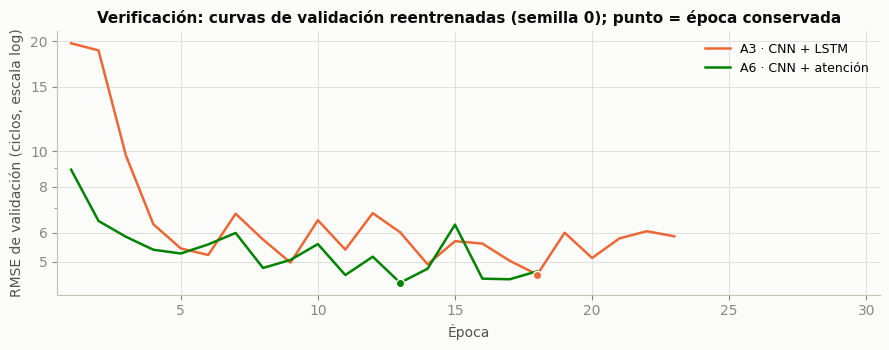

In [14]:
verif = run_many([dict(arch=a, seed=0, base_dir=VERIF_DIR) for a in ("A3", "A6")],
                 label="  ")

if not SMOKE_TEST:
    rows = []
    for r in verif:
        ref_dir = os.path.join(RUNS_DIR, r["id"])          # misma corrida, copiada de v02
        with open(os.path.join(ref_dir, "run.json"), encoding="utf-8") as fh:
            ref = json.load(fh)
        ref_preds = np.load(os.path.join(ref_dir, "preds.npz"))
        h_new, h_ref = np.array(r["history"]["val_rmse"]), np.array(ref["history"]["val_rmse"])
        rows.append({
            "Arquitectura": ARCH_IDS[r["arch"]],
            "Épocas (v02 / ahora)": f"{len(h_ref)} / {len(h_new)}",
            "Mejor época (v02 / ahora)": f"{ref['best_epoch']} / {r['best_epoch']}",
            # Si las longitudes difieren, la diferencia se marca como infinita
            "Dif. historial": (float(np.max(np.abs(h_new - h_ref)))
                               if len(h_new) == len(h_ref) else np.inf),
            "Dif. pred. validación": float(np.max(np.abs(r["val_pred"] - ref_preds["val"]))),
            "Dif. pred. evaluación": float(np.max(np.abs(r["eval_pred"] - ref_preds["eval"]))),
        })
    comp = pd.DataFrame(rows)
    print(comp.to_string(index=False))
    ok = (comp[["Dif. historial", "Dif. pred. validación", "Dif. pred. evaluación"]] == 0).all().all()
    print("\nOK: el reentrenamiento coincide exactamente con v02" if ok
          else "\nERROR: el reentrenamiento difiere de v02, revisar")
    assert ok

# Curvas de las dos corridas reentrenadas, en el eje común de 1 a 30 épocas.
# Cada curva termina donde la detuvo el early stopping; el punto marca la época conservada.
fig, ax = plt.subplots(figsize=(9, 3.6))
for r in verif:
    hist = r["history"]["val_rmse"]
    ax.plot(np.arange(1, len(hist) + 1), hist, color=ARCH_COLORS[r["arch"]], lw=1.8,
            label=ARCH_LABELS[r["arch"]])
    ax.scatter([r["best_epoch"]], [hist[r["best_epoch"] - 1]], s=36, color=ARCH_COLORS[r["arch"]],
               edgecolor=SURFACE, linewidth=1, zorder=3)
ax.set_yscale("log")
ax.yaxis.set_major_locator(mticker.FixedLocator([4, 5, 6, 8, 10, 15, 20, 30]))
ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
set_epoch_axis(ax)
ax.set_ylabel("RMSE de validación (ciclos, escala log)")
ax.set_title("Verificación: curvas de validación reentrenadas (semilla 0); punto = época conservada")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()

## 0.15 Punto de partida: configuración final de v03

Se cargan desde disco, sin entrenar, las tres configuraciones contra las que se compara
el pooling en la etapa 1. Son las mismas corridas de v03 (copiadas de v02):

- **A6, α = 2:** la configuración final de v03.
- **A6, α = 1 (MSE):** la misma arquitectura con la pérdida simétrica.
- **A3, α = 1:** la base sin atención.

Solo se muestra la validación (motores 18 y 20). Los resultados en el conjunto de prueba
de estas configuraciones están en `RULv03.ipynb`, etapa 3.

In [15]:
# Configuraciones de referencia: (arquitectura, alfa) y su nombre en las tablas
REFERENCE_CONFIGS = [(FINAL_V03["arch"], FINAL_V03["alpha"], "Final v03 (A6, α = 2)"),
                     ("A6", 1.0, "A6, MSE"),
                     (BASE_ARCH, 1.0, "Base (A3, MSE)")]

# Una corrida por configuración y semilla; todas existen en disco, así que solo se cargan
reference = run_many([dict(arch=a, alpha=al, seed=s) for a, al, _ in REFERENCE_CONFIGS
                      for s in SEEDS], label="  ")
ref_val = records_to_df(reference, "val")           # métricas de cada corrida en validación
# Columna con el nombre legible de cada configuración, para agrupar en la tabla
_names_cfg = {(a, al): name for a, al, name in REFERENCE_CONFIGS}
ref_val.insert(0, "Configuración", [_names_cfg[(a, al)] for a, al in zip(ref_val["arch"], ref_val["alpha"])])
print("Validación (motores 18 y 20), mediana [mín. – máx.] sobre semillas:")
print(summary_table(ref_val, "Configuración").to_string(index=False))

  A6 · global · alpha=2 · semilla 0 | mejor época  8/13 | caché
  A6 · global · alpha=2 · semilla 1 | mejor época 13/18 | caché
  A6 · global · alpha=2 · semilla 2 | mejor época 12/17 | caché
  A6 · global · alpha=2 · semilla 3 | mejor época 18/23 | caché
  A6 · global · alpha=2 · semilla 4 | mejor época 15/20 | caché
  A6 · global · alpha=1 · semilla 0 | mejor época 13/18 | caché
  A6 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A6 · global · alpha=1 · semilla 2 | mejor época 25/30 | caché
  A6 · global · alpha=1 · semilla 3 | mejor época 16/21 | caché
  A6 · global · alpha=1 · semilla 4 | mejor época 30/30 | caché
  A3 · global · alpha=1 · semilla 0 | mejor época 18/23 | caché
  A3 · global · alpha=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · alpha=1 · semilla 2 | mejor época  9/14 | caché
  A3 · global · alpha=1 · semilla 3 | mejor época  5/10 | caché
  A3 · global · alpha=1 · semilla 4 | mejor época 10/15 | caché
-> 15 corridas en 0.0 min (15 desde cach

# Etapa 1 — Pooling: bibliografía y experimento

**Pedido de la Reunión 05:** investigar por qué la red convolucional no tiene una capa de
*pooling* (max pooling), siendo lo habitual en las redes convolucionales.

**Pregunta:** ¿agregar max pooling a A6 mejora la estimación del RUL cerca del fallo?

**Configuración:** A6 sin pooling y sus dos variantes con pooling (sección 0.8),
normalización global, α = 1 y α = 2, 5 semillas. Las corridas de A6 sin pooling son las
de v02; las 20 de A6-P1 y A6-P2 son nuevas.

**Criterio de adopción (pre-registrado en la sección 0.12):** con α = 2 se toma la
variante con pooling de menor mediana de RMSE final en validación; reemplaza a A6 solo si
su mediana es menor **y** le gana a A6 en al menos 4 de las 5 semillas.

**Alcance:** solo validación (motores 18 y 20). El conjunto de prueba no se consulta en
esta etapa.

## 1.1 Qué dice la bibliografía

**Qué hace el pooling.** Una capa de pooling reemplaza cada tramo de la salida de una
convolución por un resumen: su máximo (*max pooling*) o su promedio (*average pooling*).
En las redes para imágenes cumple dos funciones: reduce el tamaño de los mapas de
características, y con ello el costo de las capas siguientes, y hace que la
representación sea aproximadamente invariante a desplazamientos pequeños de la entrada
(Goodfellow, Bengio y Courville, 2016, sección 9.3). En una serie de tiempo, el
"desplazamiento" es temporal: con max pooling de 2, da lo mismo si un pico ocurrió en el
paso 7 o en el 8.

**Qué hacen los trabajos en que se inspiran las arquitecturas.** Se revisaron los textos
originales; las citas son textuales.

| Trabajo | Datos | ¿Usa pooling? |
|---|---|---|
| Sateesh Babu, Zhao y Li (2016), inspira A1 | C-MAPSS (PHM 2008), ventanas de 15 pasos | Sí: dos capas de *average pooling* de tamaño 2, sin solapamiento (p. 9) |
| Li, Ding y Sun (2018), inspira A1 | C-MAPSS, ventanas de 30 pasos y 14 sensores | **No, de forma explícita** (sección 2.1, p. 3) |
| Li, Wang y Li (2022), inspira A5 | N-CMAPSS, entradas de 400 × 42 | Sí: CNN 2D con tres capas de max pooling de 5 × 5 (tabla 2, p. 14) |

Li, Ding y Sun (2018) justifican la omisión así: el pooling "is able to extract the most
significant local information in each feature map" y reduce la dimensión de las
características, por lo que "is well suited for very high-dimensional problems such as
image processing. However, while computing efficiency can be improved by this
operation, noticeable useful information is filtered to some extent. Hence, despite the
popular employment of pooling in convolution neural network, pooling is not suggested in
this prognostic problem where the raw feature dimension is comparatively low."

de Oliveira da Costa et al. (2019), que inspira A4, resume ese mismo trabajo como
"1D convolutions in sequence without pooling operations".

**Por qué A6 no tiene pooling.** A1 y A6 siguen el diseño de Li, Ding y Sun (2018), que
usa ventanas de 30 pasos, igual que este trabajo, y omite el pooling a propósito. Por
eso la red no tenía pooling: fue una decisión heredada de esa referencia, no un descuido,
aunque en v01–v03 no se había comprobado con datos. Los argumentos en contra del pooling
en este problema son:

1. **La ventana ya es corta.** 30 pasos son 5 minutos de vuelo; con pooling quedan 15 o 7.
2. **El costo no es un problema.** Las ventanas tienen 30 × 18 valores, no los millones
   de una imagen. El pooling no cambia el número de parámetros de A6 (sección 0.8) y el
   ahorro de cómputo es pequeño.
3. **La atención ya resume el eje temporal.** A6 termina en una atención que pondera los
   30 pasos. El pooling haría un resumen fijo antes del resumen aprendido.

El argumento a favor es la tolerancia a desplazamientos y al ruido entre pasos vecinos.
Ninguno de estos argumentos se ha medido en N-CMAPSS con esta arquitectura; por eso se
hace el experimento.

**Referencias:**

- Goodfellow, I., Bengio, Y. y Courville, A. (2016). *Deep Learning*. MIT Press, cap. 9.
- Sateesh Babu, G., Zhao, P. y Li, X.-L. (2016). Deep convolutional neural network based
  regression approach for estimation of remaining useful life. *DASFAA 2016*, LNCS 9642,
  214–228.
- Li, X., Ding, Q. y Sun, J.-Q. (2018). Remaining useful life estimation in prognostics
  using deep convolution neural networks. *Reliability Engineering & System Safety*, 172,
  1–11.
- Li, H., Wang, Z. y Li, Z. (2022). An enhanced CNN-LSTM remaining useful life prediction
  model for aircraft engine with attention mechanism. *PeerJ Computer Science*, 8, e1084.
  https://doi.org/10.7717/peerj-cs.1084
- de Oliveira da Costa, P. R., Akçay, A., Zhang, Y. y Kaymak, U. (2019). Attention and
  long short-term memory network for remaining useful lifetime predictions of turbofan
  engine degradation. *International Journal of Prognostics and Health Management*, 10(4).

## 1.2 Corridas

20 corridas nuevas: A6-P1 y A6-P2, con α = 1 y α = 2, 5 semillas. Las corridas de A6 sin
pooling con α = 1 y α = 2 ya se cargaron en la sección 0.15.

In [16]:
STAGE1_ALPHAS = [1.0, 2.0]          # pérdida simétrica (MSE) y la elegida en v03
STAGE1_ARCHS = ["A6"] + POOL_ARCHS  # orden en tablas y figuras: sin pooling primero

# Corridas nuevas: una por variante, valor de alfa y semilla
pool_runs = run_many([dict(arch=a, alpha=al, seed=s) for a in POOL_ARCHS
                      for al in STAGE1_ALPHAS for s in SEEDS], label="  ")
# Se juntan con las de A6 sin pooling (alfa 1 y 2) ya cargadas en la sección 0.15
stage1 = [r for r in reference if r["arch"] == "A6"] + pool_runs
s1_val = records_to_df(stage1, "val")    # métricas de cada corrida sobre validación
s1_val.to_csv(os.path.join(OUT_DIR, "etapa1_val.csv"), index=False, encoding="utf-8-sig")

  A6P1 · global · alpha=1 · semilla 0 | mejor época 23/28 | caché
  A6P1 · global · alpha=1 · semilla 1 | mejor época 22/27 | caché
  A6P1 · global · alpha=1 · semilla 2 | mejor época  6/11 | caché
  A6P1 · global · alpha=1 · semilla 3 | mejor época 22/27 | caché
  A6P1 · global · alpha=1 · semilla 4 | mejor época 17/22 | caché
  A6P1 · global · alpha=2 · semilla 0 | mejor época 13/18 | caché
  A6P1 · global · alpha=2 · semilla 1 | mejor época  6/11 | caché
  A6P1 · global · alpha=2 · semilla 2 | mejor época  7/12 | caché
  A6P1 · global · alpha=2 · semilla 3 | mejor época 14/19 | caché
  A6P1 · global · alpha=2 · semilla 4 | mejor época 15/20 | caché
  A6P2 · global · alpha=1 · semilla 0 | mejor época  9/14 | caché
  A6P2 · global · alpha=1 · semilla 1 | mejor época 13/18 | caché
  A6P2 · global · alpha=1 · semilla 2 | mejor época 15/20 | caché
  A6P2 · global · alpha=1 · semilla 3 | mejor época 18/23 | caché
  A6P2 · global · alpha=1 · semilla 4 | mejor época  5/10 | caché
  A6P2 · g

## 1.3 Resultados en validación

Primera tabla: mediana [mín. – máx.] sobre las 5 semillas, por variante y valor de α.
Segunda tabla: el RMSE en la zona final de cada semilla con α = 2, que es la comparación
que decide.

In [17]:
# Orden de las filas: primero alfa = 2 (la comparación que decide), y dentro de cada alfa,
# A6 sin pooling, A6-P1 y A6-P2
_sorted = s1_val.assign(_k=s1_val["arch"].map(STAGE1_ARCHS.index)).sort_values(
    ["alpha", "_k"], ascending=[False, True])
tab1 = summary_table(_sorted, ["alpha", "arch"], MAIN_METRICS + ["RMSE final u18", "RMSE final u20"])
tab1.insert(2, "Variante", tab1["arch"].map(ARCH_LABELS))
tab1 = tab1.drop(columns="arch").rename(columns={"alpha": "α"})
print("Validación — mediana [mín. – máx.] sobre semillas")
display(tab1)

# RMSE final por semilla con alfa = 2; las columnas Dif. son variante - A6 (negativo = mejora)
_a2 = s1_val[s1_val["alpha"] == FINAL_V03["alpha"]]
seed_tab = _a2.pivot(index="seed", columns="arch", values="RMSE final")[STAGE1_ARCHS]
for k in POOL_ARCHS:
    seed_tab[f"Dif. {ARCH_IDS[k]}"] = seed_tab[k] - seed_tab["A6"]
seed_tab = seed_tab.rename(columns=ARCH_IDS)
print(f"\nRMSE en zona final por semilla, α = {FINAL_V03['alpha']:g} (validación)")
display(seed_tab.round(3))

Validación — mediana [mín. – máx.] sobre semillas


,α,Variante,n,RMSE final,Sobreest. media final,Score NASA final,RMSE,Sesgo,RMSE final u18,RMSE final u20
0,2.0,A6 · CNN + atención,5,1.83 [1.60 – 2.17],0.77 [0.62 – 0.87],0.14 [0.13 – 0.17],4.53 [4.43 – 4.77],-0.93 [-1.53 – -0.21],2.01 [1.33 – 2.10],1.92 [1.59 – 2.32]
1,2.0,"A6-P1 · CNN + atención, pooling tras la 1.ª conv.",5,2.03 [1.71 – 2.54],0.50 [0.45 – 1.17],0.17 [0.13 – 0.19],4.46 [4.24 – 4.74],-0.20 [-0.77 – 0.21],1.91 [1.46 – 2.89],1.95 [1.46 – 2.51]
2,2.0,"A6-P2 · CNN + atención, pooling tras cada conv.",5,2.03 [1.61 – 2.26],0.49 [0.32 – 0.88],0.15 [0.11 – 0.17],5.17 [4.67 – 5.59],-1.83 [-2.89 – -1.34],2.41 [1.72 – 2.63],1.60 [1.48 – 1.95]
3,1.0,A6 · CNN + atención,5,2.00 [1.77 – 3.02],1.04 [0.80 – 1.48],0.18 [0.14 – 0.25],4.38 [4.35 – 4.91],-0.08 [-0.23 – 1.01],1.47 [1.18 – 3.28],2.57 [1.92 – 2.80]
4,1.0,"A6-P1 · CNN + atención, pooling tras la 1.ª conv.",5,1.93 [1.82 – 2.20],1.10 [0.65 – 1.32],0.16 [0.14 – 0.18],4.47 [4.21 – 4.77],0.65 [-0.79 – 1.29],1.34 [0.98 – 2.17],2.50 [1.93 – 2.86]
5,1.0,"A6-P2 · CNN + atención, pooling tras cada conv.",5,1.71 [1.56 – 2.18],0.59 [0.33 – 1.29],0.13 [0.12 – 0.18],4.64 [4.49 – 4.96],-1.32 [-1.71 – 0.48],1.70 [1.49 – 2.05],1.51 [1.13 – 2.61]



RMSE en zona final por semilla, α = 2 (validación)


arch,A6,A6-P1,A6-P2,Dif. A6-P1,Dif. A6-P2
seed,,,,,
0,1.831,1.711,2.187,-0.120,0.356
1,2.110,2.543,1.610,0.434,-0.499
2,1.603,2.422,2.026,0.819,0.423
3,1.636,1.892,2.265,0.256,0.629
4,2.168,2.027,1.874,-0.141,-0.294


## 1.4 Aplicación de la regla de adopción

In [18]:
N_BETTER_MIN = 4                     # semillas en que la variante debe ganar a A6 (de 5)

_med2 = _a2.groupby("arch")["RMSE final"].median()       # mediana por variante, alfa = 2
POOL_CANDIDATE = _med2[POOL_ARCHS].idxmin()               # paso 1: mejor variante con pooling
# Paso 2: comparación semilla con semilla contra A6 sin pooling
_by_seed = _a2.pivot(index="seed", columns="arch", values="RMSE final")
_n_better = int((_by_seed[POOL_CANDIDATE] < _by_seed["A6"]).sum())
_lower_median = bool(_med2[POOL_CANDIDATE] < _med2["A6"])
POOL_ADOPTED = _lower_median and _n_better >= N_BETTER_MIN
# Arquitectura que sigue en adelante: la variante con pooling si se adopta, si no, A6
STAGE1_CHOICE = POOL_CANDIDATE if POOL_ADOPTED else "A6"

print(f"Mediana de RMSE final con α = {FINAL_V03['alpha']:g}:")
for k in STAGE1_ARCHS:
    print(f"   {ARCH_LABELS[k]:<48} {_med2[k]:.3f}")
print(f"\nMejor variante con pooling: {ARCH_IDS[POOL_CANDIDATE]}")
print(f"   (a) mediana menor que A6: {'sí' if _lower_median else 'no'}")
print(f"   (b) mejor que A6 en {_n_better} de {len(_by_seed)} semillas "
      f"(se exigen {N_BETTER_MIN}): {'sí' if _n_better >= N_BETTER_MIN else 'no'}")
print(f"\nDecisión: {'se adopta ' + ARCH_IDS[POOL_CANDIDATE] if POOL_ADOPTED else 'no se adopta el pooling'}"
      f" -> arquitectura vigente: {ARCH_LABELS[STAGE1_CHOICE]}")

# La decisión se registra junto a los criterios
selection["decisiones"]["etapa_1"] = {
    "variante_candidata": POOL_CANDIDATE,
    "mediana_rmse_final_val": {k: round(float(_med2[k]), 4) for k in STAGE1_ARCHS},
    "mediana_menor_que_A6": _lower_median,
    "semillas_mejor_que_A6": _n_better,
    "pooling_adoptado": bool(POOL_ADOPTED),
    "arquitectura_vigente": STAGE1_CHOICE,
}
if not SMOKE_TEST:
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)

Mediana de RMSE final con α = 2:
   A6 · CNN + atención                              1.831
   A6-P1 · CNN + atención, pooling tras la 1.ª conv. 2.027
   A6-P2 · CNN + atención, pooling tras cada conv.  2.026

Mejor variante con pooling: A6-P2
   (a) mediana menor que A6: no
   (b) mejor que A6 en 2 de 5 semillas (se exigen 4): no

Decisión: no se adopta el pooling -> arquitectura vigente: A6 · CNN + atención


## 1.5 Figuras

### Comparación por semilla

Fila superior: α = 2, la comparación que decide. Fila inferior: α = 1 (MSE), como
complemento. Cada punto es una semilla, el trazo negro marca la mediana y la línea
horizontal, el rango.

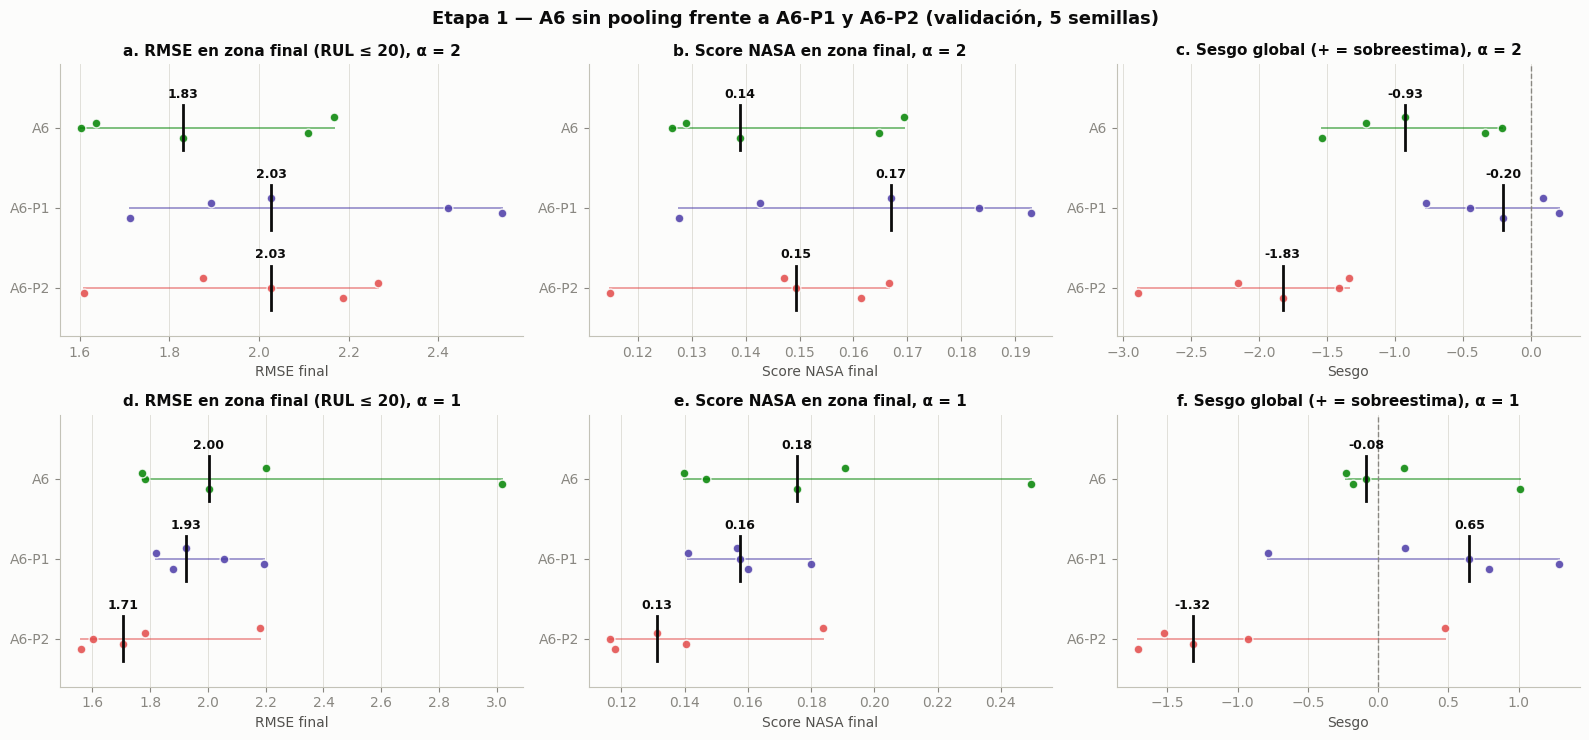

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for row, alpha in enumerate([FINAL_V03["alpha"], 1.0]):
    sub = s1_val[s1_val["alpha"] == alpha]
    for col, (metric, title) in enumerate((("RMSE final", "RMSE en zona final (RUL ≤ 20)"),
                                           ("Score NASA final", "Score NASA en zona final"),
                                           ("Sesgo", "Sesgo global (+ = sobreestima)"))):
        ax = axes[row, col]
        seed_dotplot(ax, sub, metric, STAGE1_ARCHS, labels=ARCH_IDS)
        ax.set_title(f"{'abcdef'[3 * row + col]}. {title}, α = {alpha:g}")
        if metric == "Sesgo":
            ax.axvline(0, color=MUTED, lw=1, ls="--")   # referencia: sin sesgo
fig.suptitle("Etapa 1 — A6 sin pooling frente a A6-P1 y A6-P2 (validación, 5 semillas)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa1_pooling.png"), dpi=160, bbox_inches="tight")
plt.show()

### Curvas de aprendizaje y convergencia

RMSE de validación por época, en el eje común de 1 a 30 épocas. Cada línea tenue es una
semilla y termina donde la detuvo el early stopping; el punto marca la época que se
conservó; la línea gruesa es la mediana entre semillas.

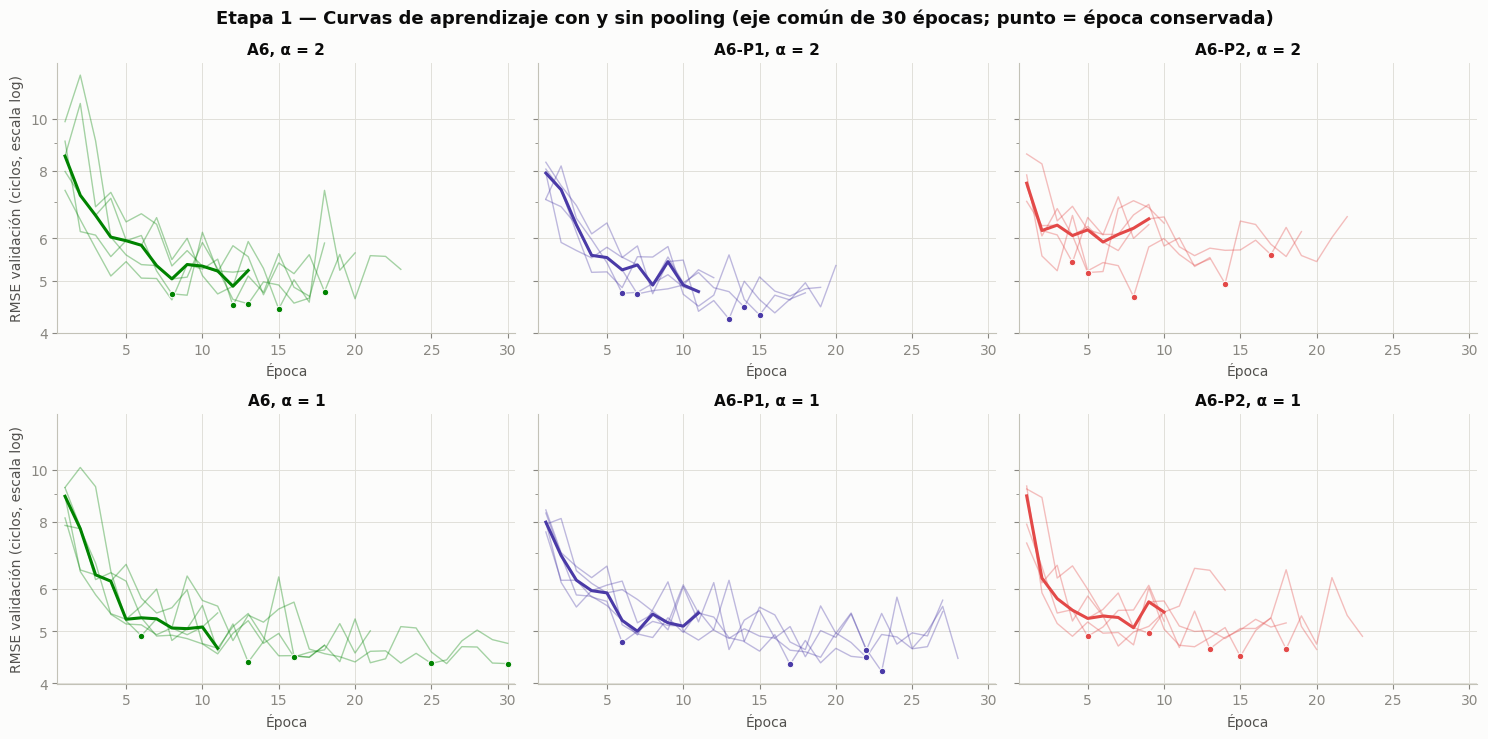

,α,Variante,Época conservada,Épocas entrenadas,Detenidas por el límite de 30,Segundos por época
0,2.0,A6,13 [8 – 18],18 [13 – 23],0,2.8 [2.8 – 3.4]
1,2.0,A6-P1,13 [6 – 15],18 [11 – 20],0,2.8 [2.8 – 2.9]
2,2.0,A6-P2,8 [4 – 17],13 [9 – 22],0,3.0 [2.9 – 3.0]
3,1.0,A6,16 [6 – 30],21 [11 – 30],1,3.9 [3.3 – 4.3]
4,1.0,A6-P1,22 [6 – 23],27 [11 – 28],0,2.8 [2.7 – 2.8]
5,1.0,A6-P2,13 [5 – 18],18 [10 – 23],0,2.9 [2.9 – 2.9]


In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True, sharey=True)
for row, alpha in enumerate([FINAL_V03["alpha"], 1.0]):
    for col, k in enumerate(STAGE1_ARCHS):
        ax = axes[row, col]
        recs = [r for r in stage1 if r["arch"] == k and r["alpha"] == alpha]
        seed_curves(ax, recs, "val_rmse", color=ARCH_COLORS[k])
        ax.set_title(f"{ARCH_IDS[k]}, α = {alpha:g}")
        # Escala logarítmica, igual que en v03, para ver la zona de convergencia
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(mticker.FixedLocator([4, 5, 6, 8, 10, 15, 20, 30]))
        ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
        ax.yaxis.set_minor_formatter(mticker.NullFormatter())
        set_epoch_axis(ax)                            # eje común de 1 a 30 épocas
        ax.tick_params(axis="x", labelbottom=True)    # números del eje en ambas filas
for ax in axes[:, 0]:
    ax.set_ylabel("RMSE validación (ciclos, escala log)")
fig.suptitle("Etapa 1 — Curvas de aprendizaje con y sin pooling (eje común de 30 épocas; "
             "punto = época conservada)", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa1_curvas.png"), dpi=160, bbox_inches="tight")
plt.show()

# Tabla de convergencia y costo de cada variante
conv_rows = []
for alpha in [FINAL_V03["alpha"], 1.0]:
    for k in STAGE1_ARCHS:
        recs = [r for r in stage1 if r["arch"] == k and r["alpha"] == alpha]
        best = [r["best_epoch"] for r in recs]       # época conservada de cada semilla
        trained = [r["epochs"] for r in recs]        # épocas entrenadas de cada semilla
        conv_rows.append({
            "α": alpha, "Variante": ARCH_IDS[k],
            "Época conservada": med_range(best, "{:.0f}"),
            "Épocas entrenadas": med_range(trained, "{:.0f}"),
            # Detenida por el límite: entrenó 30 épocas y aún no acumulaba 5 sin mejorar
            "Detenidas por el límite de 30": sum(t == MAX_EPOCHS and t - b < PATIENCE
                                                 for t, b in zip(trained, best)),
            # Las corridas de A6 son de v02 y se entrenaron en otro momento; el tiempo por
            # época sirve como referencia aproximada, no como medición controlada
            "Segundos por época": med_range([r["seconds"] / r["epochs"] for r in recs], "{:.1f}"),
        })
display(pd.DataFrame(conv_rows))

### Pesos de atención

Con pooling, la atención ya no pondera 30 pasos sino 15 (A6-P1) o 7 (A6-P2). Para
comparar las tres variantes en un mismo gráfico:

- **Eje horizontal:** cada paso después del pooling resume 2 (A6-P1) o 4 (A6-P2) pasos de
  la ventana original. Se ubica en el centro de los pasos que resume. En A6-P2, los pasos
  29 y 30 no llegan a la atención: el segundo pooling descarta el paso 15 de A6-P1, que
  no completa un tramo de 2.
- **Eje vertical:** peso × número de pasos (T). Vale 1 en todos los pasos si la atención
  pondera igual a todos (promedio simple), con cualquier T.

Se usa α = 2, en validación, promediando las 5 semillas. Se separan las ventanas de la
zona final del resto.

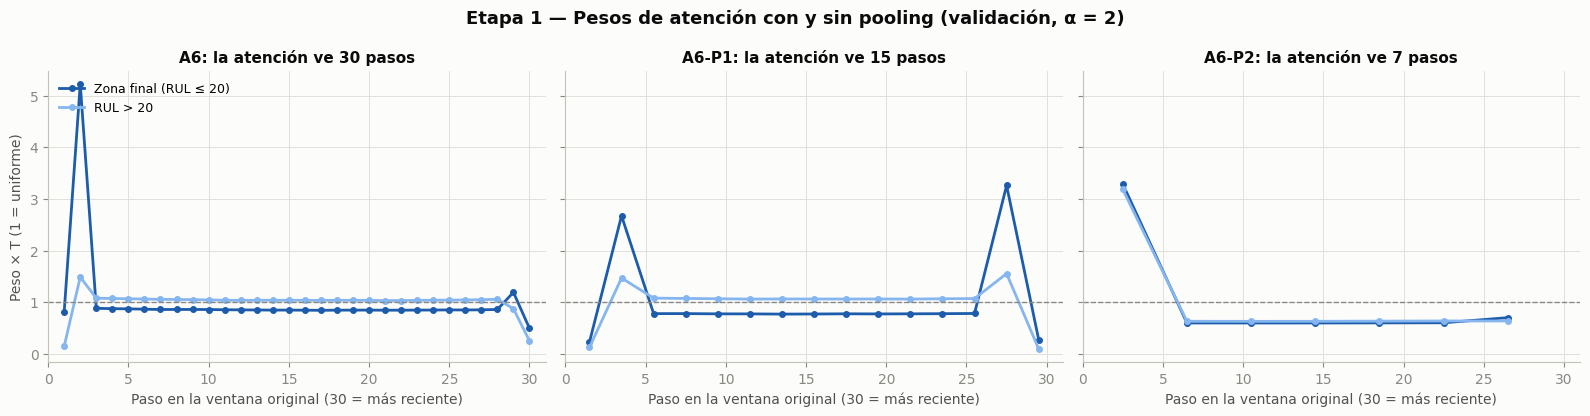

In [21]:
_Xv, _yv, _ = build_tensors("global", "oficial")["val"]
_fin = _yv <= FINAL_ZONE                                     # ventanas de la zona final
POOL_SPAN = {"A6": 1, "A6P1": 2, "A6P2": 4}                  # pasos originales por paso


def step_centers(arch, T):
    """Centro, en pasos originales (1 a 30), de cada uno de los T pasos que ve la atención."""
    span = POOL_SPAN[arch]
    return np.arange(T) * span + (span + 1) / 2


fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, k in zip(axes, STAGE1_ARCHS):
    recs = [r for r in stage1 if r["arch"] == k and r["alpha"] == FINAL_V03["alpha"]]
    # Pesos de cada semilla, forma (N ventanas, T), promediados entre semillas
    W = np.mean([predict(load_model(r), _Xv, collect_weights=True)[1] for r in recs], axis=0)
    T = W.shape[1]
    x = step_centers(k, T)
    ax.plot(x, W[_fin].mean(axis=0) * T, color="#1c5cab", lw=2, marker="o", ms=4,
            label=f"Zona final (RUL ≤ {FINAL_ZONE:g})")
    ax.plot(x, W[~_fin].mean(axis=0) * T, color="#86b6ef", lw=2, marker="o", ms=4,
            label=f"RUL > {FINAL_ZONE:g}")
    ax.axhline(1, color=MUTED, lw=1, ls="--")                # promedio uniforme
    ax.set_xlim(0, WINDOW_SIZE + 1)
    ax.set_title(f"{ARCH_IDS[k]}: la atención ve {T} pasos")
    ax.set_xlabel("Paso en la ventana original (30 = más reciente)")
axes[0].set_ylabel("Peso × T (1 = uniforme)")
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle(f"Etapa 1 — Pesos de atención con y sin pooling (validación, α = {FINAL_V03['alpha']:g})",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa1_atencion.png"), dpi=160, bbox_inches="tight")
plt.show()

## 1.6 Observación posterior: A6-P2 con MSE

En la tabla de la sección 1.3, A6-P2 con α = 1 (MSE) tiene una mediana de RMSE final más
baja que la configuración final de v03 (A6 con α = 2). Esa comparación **no estaba
prevista en la regla**, que compara variantes con el mismo α. Se revisa aquí semilla con
semilla para saber si es una diferencia consistente o un efecto de la mediana, pero el
resultado no cambia la decisión: elegir una configuración después de mirar todas las
combinaciones es justamente lo que el pre-registro busca evitar.

In [22]:
# Misma semilla = mismos pesos iniciales y mismo orden de los lotes (sección 0.8)
_final = s1_val[(s1_val["arch"] == "A6") & (s1_val["alpha"] == FINAL_V03["alpha"])].set_index("seed")
_p2mse = s1_val[(s1_val["arch"] == "A6P2") & (s1_val["alpha"] == 1.0)].set_index("seed")
post_rows = []
for m in ["RMSE final", "Score NASA final", "Sobreest. media final", "RMSE", "Sesgo"]:
    post_rows.append({
        "Métrica": m,
        "Final v03 (A6, α = 2)": med_range(_final[m]),
        "A6-P2, α = 1": med_range(_p2mse[m]),
        # El sesgo no tiene un "mejor" en una sola dirección: no se cuenta
        "Semillas en que A6-P2 con MSE es mejor": "—" if m == "Sesgo"
        else f"{int((_p2mse[m] < _final[m]).sum())} de {len(_final)}",
    })
display(pd.DataFrame(post_rows))
print("Diferencia de RMSE final por semilla (A6-P2 con MSE menos final v03):",
      np.round((_p2mse["RMSE final"] - _final["RMSE final"]).values, 4))

# Se registra como observación, separada de la decisión
selection["decisiones"]["etapa_1"]["observacion_posterior_A6P2_mse"] = {
    "mediana_rmse_final_val": round(float(_p2mse["RMSE final"].median()), 4),
    "semillas_mejor_que_final_v03": int((_p2mse["RMSE final"] < _final["RMSE final"]).sum()),
    "nota": "Comparación no prevista en la regla; no cambia la decisión.",
}
if not SMOKE_TEST:
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)

,Métrica,"Final v03 (A6, α = 2)","A6-P2, α = 1",Semillas en que A6-P2 con MSE es mejor
0,RMSE final,1.83 [1.60 – 2.17],1.71 [1.56 – 2.18],3 de 5
1,Score NASA final,0.14 [0.13 – 0.17],0.13 [0.12 – 0.18],3 de 5
2,Sobreest. media final,0.77 [0.62 – 0.87],0.59 [0.33 – 1.29],3 de 5
3,RMSE,4.53 [4.43 – 4.77],4.64 [4.49 – 4.96],2 de 5
4,Sesgo,-0.93 [-1.53 – -0.21],-1.32 [-1.71 – 0.48],—


Diferencia de RMSE final por semilla (A6-P2 con MSE menos final v03): [-0.269  -0.4041 -0.0007  0.1458  0.0132]


## 1.7 Discusión

### Respuesta al pedido: por qué la red no tiene pooling

1. **Fue una decisión de diseño heredada, con respaldo bibliográfico.** A1 y A6 siguen a
   Li, Ding y Sun (2018), que trabajan con ventanas de 30 pasos, igual que aquí, y
   desaconsejan el pooling de forma explícita porque descarta información cuando la
   dimensión de la entrada es baja. Otros trabajos sí lo usan: Sateesh Babu et al.
   (2016), con *average pooling*, y Li, Wang y Li (2022), con max pooling sobre entradas
   mucho más grandes (400 × 42).
2. **El experimento no justifica agregarlo.** Con la pérdida de la configuración final
   (α = 2), ninguna de las dos variantes mejora a A6:

| Variante (α = 2) | RMSE final, validación | Semillas en que mejora a A6 |
|---|---|---|
| A6, sin pooling | 1,83 [1,60 – 2,17] | — |
| A6-P1, pooling tras la 1.ª conv. | 2,03 [1,71 – 2,54] | 2 de 5 |
| A6-P2, pooling tras cada conv. | 2,03 [1,61 – 2,26] | 2 de 5 |

La regla pre-registrada no adopta el pooling: no se cumple ninguna de sus dos
condiciones. **La configuración final sigue siendo la de v03** y la etapa 2 (validación
cruzada y segunda evaluación en prueba) no se ejecuta. El paso 1 de la regla eligió a
A6-P2 como candidata por una diferencia de 0,001 en la mediana: A6-P1 y A6-P2 están
empatadas, y la elección entre ellas no influye en la decisión.

### El efecto del pooling depende de la pérdida

Con MSE (α = 1) el resultado es distinto: A6-P2 obtiene 1,71 [1,56 – 2,18] frente a
2,00 [1,77 – 3,02] de A6, y mejora en 4 de las 5 semillas. La columna de sesgo sugiere
por qué: **A6-P2 desplaza las predicciones hacia abajo** (sesgo global −1,32 con MSE,
frente a −0,08 de A6). Con MSE, ese desplazamiento reduce la sobreestimación en la zona
final (0,59 frente a 1,04 ciclos), que es la que más pesa en el RMSE final. Con α = 2 la
pérdida asimétrica ya produce ese desplazamiento (sesgo −0,93 en A6), y el pooling lo
exagera: A6-P2 llega a un sesgo de −1,83 y su RMSE global empeora de 4,53 a 5,17 ciclos.

En otras palabras, en estos datos el pooling y la pérdida asimétrica parecen hacer algo
parecido (bajar las predicciones) y no se suman. Esta lectura se apoya en el sesgo
observado, no en un experimento diseñado para probarla.

La sección 1.6 muestra que A6-P2 con MSE tampoco supera de forma consistente a la
configuración final: su mediana es menor (1,71 frente a 1,83), pero es mejor solo en 3
de las 5 semillas, una de ellas por 0,0007 ciclos. No habría pasado la regla de 4 de 5.

### Atención y convergencia

- **Atención:** en las tres variantes los pesos son casi planos (peso × T ≈ 1) en el
  interior de la ventana, y los picos aparecen en los pasos de los bordes, igual que en
  v03. Con el pooling, el pico se mueve con el borde: en A6-P1 aparece en el segundo y en
  el penúltimo paso, y en A6-P2 en el primer paso. La explicación más probable es el
  relleno con ceros (*padding*) de las convoluciones, que hace distintos a los pasos de
  los bordes; no se comprobó en este trabajo. El pooling no cambia la conclusión de v03:
  la atención funciona en la práctica como un promedio temporal.
- **Convergencia:** ninguna corrida con pooling llegó al límite de 30 épocas. A6-P2 con
  α = 2 conserva épocas más tempranas (mediana 8) y sus curvas son más irregulares.
- **Costo:** el tiempo por época es prácticamente el mismo (unos 3 segundos), de modo
  que en este problema el pooling no ofrece el ahorro de cómputo que justifica su uso en
  imágenes. Las corridas de A6 se entrenaron en otro momento (v02), así que la
  comparación de tiempos es aproximada.

### Limitaciones

- Solo se probó max pooling de tamaño 2, en A6. No se probaron *average pooling*, otros
  tamaños ni pooling en las arquitecturas con LSTM.
- El valor de α se eligió en v02 para A6 sin pooling. Una variante con pooling podría
  rendir mejor con otro α; buscarlo sería repetir la etapa 2 de v03 para cada variante,
  y quedó fuera del alcance acordado.
- Cinco semillas por configuración: diferencias de 0,1 a 0,2 ciclos en la mediana están
  dentro de la variación entre semillas.

# Etapa 3 — Regímenes de operación: revisión "doble clic"

Esta sección profundiza en el análisis de regímenes de la etapa 4 de v03. No modifica la
configuración final. Responde dos pedidos de la Reunión 05:

1. **Verificar si el clustering usa todas las dimensiones o solo dos** (velocidad y
   altitud), porque la figura de v03 daba esa impresión.
2. **Correr el clustering con más grupos** para intentar mejorar la silueta de Spectral
   Clustering.

Además, con la decisión confirmada en el plan, se compara el agrupamiento sobre las 4
condiciones de vuelo W con un agrupamiento sobre las **18 variables que recibe el
modelo** (W + X_s).

**Dos aclaraciones sobre lo conversado en la reunión:**

- **La silueta de 0,45 y los 18 grupos son dos resultados distintos de v03.** Spectral
  Clustering obtuvo su mejor silueta (0,445) con K = 2. Los 18 grupos son de DBSCAN, cuya
  silueta fue negativa (−0,48).
- **No existe un conjunto de 16 variables en los datos.** W tiene 4 variables, X_s tiene
  14 y el modelo recibe 18.

**Protocolo:** el mismo de v03. Los métodos se ajustan sobre la misma submuestra de 8.000
registros de los motores de entrenamiento, con los datos estandarizados usando solo esos
motores. La calidad se mide con la silueta y el índice de Davies-Bouldin, y el sentido
físico con el índice de Rand ajustado frente a las fases de vuelo (ver v03, etapa 4).
Esta etapa usa solo los motores de desarrollo; el conjunto de prueba no se consulta.

## 3.1 Datos, fases de vuelo y los dos espacios de agrupamiento

Las fases de vuelo se calculan igual que en v03: con la tasa de cambio de la altitud y un
umbral de 10 pies por paso de 10 s (la justificación del umbral está en v03, sección 4.1).

Se definen dos espacios:

- **W (4D):** altitud, Mach, TRA y T2, el espacio usado en v03.
- **W + X_s (18D):** las 18 variables que recibe el modelo.

En ambos casos, cada variable se estandariza con la media y la desviación estándar de
los motores de entrenamiento.

In [23]:
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA

N_W = len(var_names["W"])            # las primeras 4 columnas de 'features' son W
PHASE_NAMES = ["Ascenso", "Nivelado", "Descenso"]
PHASE_COLORS = {"Ascenso": "#eb6834", "Nivelado": "#2a78d6", "Descenso": "#1baf7a"}
PHASE_TH = 10.0                      # pies por paso de 10 s (60 pies por minuto), como en v03
CLUSTER_SAMPLE = 8000                # tamaño de la submuestra para ajustar los métodos
KNN_ASSIGN = 15                      # vecinos para asignar cada registro a un grupo
# Número de grupos que se prueba: de 2 a 20 (en v03 era de 2 a 6). En la prueba rápida
# se recorta para que termine en segundos
K_RANGE = list(range(2, 21)) if not SMOKE_TEST else [2, 3]


def flight_bounds(d):
    """Límites [inicio, fin) de cada vuelo: segmentos contiguos con el mismo (motor, ciclo)."""
    key = np.stack([d["unit"], d["cycle"]], axis=1)
    change = np.any(np.diff(key, axis=0) != 0, axis=1)
    return np.concatenate([[0], np.where(change)[0] + 1, [len(d["unit"])]])


def climb_rate(d):
    """Tasa de cambio de la altitud de cada registro (pies por paso), suavizada dentro de su vuelo."""
    alt = d["features"][:, 0]                         # altitud, en pies
    rate = np.zeros(len(alt))
    b = flight_bounds(d)
    for s, e in zip(b[:-1], b[1:]):
        if e - s < 3:
            continue
        r = np.gradient(alt[s:e])                     # diferencia entre pasos vecinos
        # Mediana móvil de 5 pasos para que el ruido no cambie la fase de un paso a otro
        rate[s:e] = pd.Series(r).rolling(5, center=True, min_periods=1).median().values
    return rate


def flight_phases(d, th=PHASE_TH):
    """Fase de vuelo de cada registro: 0 = ascenso, 1 = nivelado, 2 = descenso."""
    rate = climb_rate(d)
    phase = np.ones(len(rate), dtype=int)             # por defecto, nivelado
    phase[rate > th] = 0
    phase[rate < -th] = 2
    return phase


phase_dev = flight_phases(dev)
_tr = np.isin(dev["unit"], TRAIN_UNITS)               # registros de los motores de entrenamiento

# Columnas de cada espacio dentro de 'features' (las 4 primeras son W, las 14 siguientes X_s)
SPACES = {"W (4D)": list(range(N_W)), "W + X_s (18D)": list(range(NUM_FEATURES))}
Z_DEV, SPACE_SCALERS = {}, {}
for space, cols in SPACES.items():
    # Estandarización ajustada solo con los registros de entrenamiento (sin fuga)
    SPACE_SCALERS[space] = StandardScaler().fit(dev["features"][_tr][:, cols])
    Z_DEV[space] = SPACE_SCALERS[space].transform(dev["features"][:, cols])

# Submuestra común: los mismos 8.000 registros de entrenamiento de v03 (misma semilla)
SUB = np.random.default_rng(0).choice(np.where(_tr)[0], size=CLUSTER_SAMPLE, replace=False)
XS = {space: Z_DEV[space][SUB] for space in SPACES}   # matriz que recibe cada método

for space, cols in SPACES.items():
    print(f"{space:<15} matriz de entrada {str(XS[space].shape):<12} columnas: "
          f"{[FEATURE_NAMES[c] for c in cols]}")
print("\nFracción de registros por fase de vuelo (entrenamiento):")
for p, name in enumerate(PHASE_NAMES):
    print(f"   {name:<9} {100 * np.mean(phase_dev[_tr] == p):5.1f} %")

W (4D)          matriz de entrada (8000, 4)    columnas: ['alt', 'Mach', 'TRA', 'T2']
W + X_s (18D)   matriz de entrada (8000, 18)   columnas: ['alt', 'Mach', 'TRA', 'T2', 'T24', 'T30', 'T48', 'T50', 'P15', 'P2', 'P21', 'P24', 'Ps30', 'P40', 'P50', 'Nf', 'Nc', 'Wf']

Fracción de registros por fase de vuelo (entrenamiento):
   Ascenso    30.3 %
   Nivelado   47.0 %
   Descenso   22.7 %


## 3.2 Verificación: ¿el clustering de v03 usaba 4 dimensiones o 2?

Tres comprobaciones:

1. **La matriz de entrada.** La celda anterior imprime su forma: `(8000, 4)`, con las
   columnas altitud, Mach, TRA y T2. Los métodos reciben las 4 columnas.
2. **Si las 4 variables aportan información distinta.** Se calculan las correlaciones
   entre ellas y un análisis de componentes principales (PCA). El PCA busca las
   direcciones en que los datos varían más; si dos componentes explican casi toda la
   varianza, los datos son en la práctica bidimensionales, aunque tengan 4 columnas.
3. **Una prueba directa.** Se ajusta k-means con K = 2 sobre las 4 variables y otra vez
   sobre solo altitud y Mach. Si el clustering de v03 hubiera usado solo esas dos, ambos
   darían los mismos grupos (Rand ajustado = 1).

In [24]:
_wz_tr = Z_DEV["W (4D)"][_tr]                         # W estandarizado, todos los registros de entrenamiento
print("Correlación entre las variables de W (registros de entrenamiento):")
display(pd.DataFrame(np.corrcoef(_wz_tr.T), index=var_names["W"], columns=var_names["W"]).round(3))

pca_w = PCA().fit(_wz_tr)
pca_tab = pd.DataFrame({
    "Componente": [f"CP{i + 1}" for i in range(N_W)],
    "Varianza explicada (%)": np.round(100 * pca_w.explained_variance_ratio_, 1),
    "Acumulada (%)": np.round(100 * np.cumsum(pca_w.explained_variance_ratio_), 1),
})
# Peso de cada variable original en cada componente (signo y magnitud)
for j, name in enumerate(var_names["W"]):
    pca_tab[f"Peso {name}"] = np.round(pca_w.components_[:, j], 2)
print("\nPCA de W estandarizado:")
display(pca_tab)

# Prueba directa: k-means K = 2 con las 4 variables frente a solo altitud y Mach
_lab_4d = KMeans(2, n_init=10, random_state=0).fit_predict(XS["W (4D)"])
_lab_2d = KMeans(2, n_init=10, random_state=0).fit_predict(XS["W (4D)"][:, :2])
_ari_42 = adjusted_rand_score(_lab_4d, _lab_2d)
print(f"\nk-means K = 2: Rand ajustado entre el agrupamiento con 4 variables y con solo "
      f"altitud y Mach = {_ari_42:.3f}")
print(f"   Registros que cambian de grupo: {100 * min(np.mean(_lab_4d != _lab_2d), np.mean(_lab_4d == _lab_2d)):.1f} %")

Correlación entre las variables de W (registros de entrenamiento):


,alt,Mach,TRA,T2
alt,1.000,0.924,0.503,-0.982
Mach,0.924,1.000,0.494,-0.837
TRA,0.503,0.494,1.000,-0.482
T2,-0.982,-0.837,-0.482,1.000



PCA de W estandarizado:


,Componente,Varianza explicada (%),Acumulada (%),Peso alt,Peso Mach,Peso TRA,Peso T2
0,CP1,79.199997,79.199997,0.55,0.53,0.37,-0.53
1,CP2,16.600000,95.800003,-0.22,-0.18,0.93,0.23
2,CP3,4.200000,100.000000,-0.15,0.79,-0.03,0.60
3,CP4,0.000000,100.000000,0.79,-0.27,0.00,0.55



k-means K = 2: Rand ajustado entre el agrupamiento con 4 variables y con solo altitud y Mach = 0.802
   Registros que cambian de grupo: 5.2 %


### Las 6 proyecciones por pares de W

La figura de v03 mostraba solo el plano Mach–altitud. Aquí se muestran los 6 pares
posibles de las 4 variables. Fila superior: coloreado por fase de vuelo. Fila inferior:
coloreado por el agrupamiento k-means con K = 2 de v03, ajustado sobre las 4 variables.

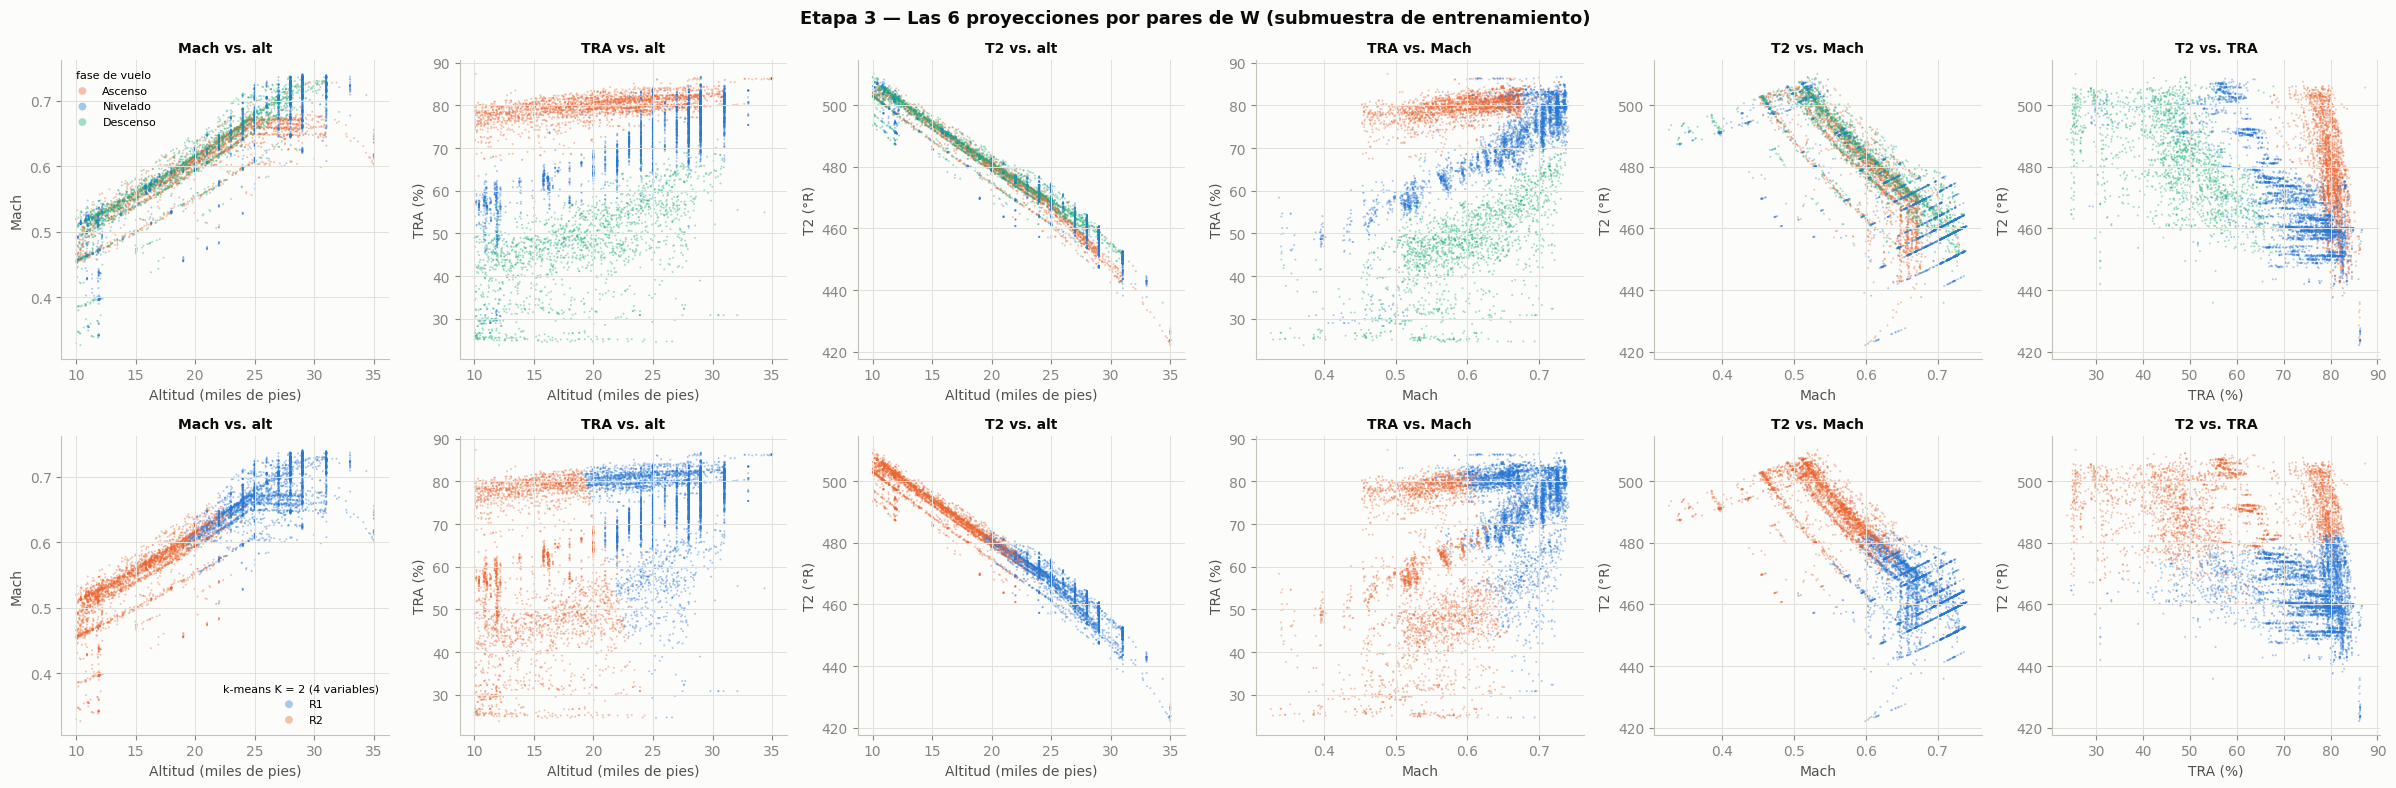

In [25]:
_W_UNITS = {"alt": "Altitud (miles de pies)", "Mach": "Mach", "TRA": "TRA (%)", "T2": "T2 (°R)"}
_W_SCALE = {"alt": 1e-3, "Mach": 1.0, "TRA": 1.0, "T2": 1.0}    # altitud en miles de pies
_w_phys = dev["features"][SUB, :N_W]                              # W en unidades físicas
_pairs = [(i, j) for i in range(N_W) for j in range(i + 1, N_W)]  # los 6 pares (i < j)
_CL_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]

fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for row, (lab, names, title) in enumerate((
        (phase_dev[SUB], PHASE_NAMES, "fase de vuelo"),
        (_lab_4d, None, "k-means K = 2 (4 variables)"))):
    for col, (i, j) in enumerate(_pairs):
        ax = axes[row, col]
        xi, yj = var_names["W"][i], var_names["W"][j]
        for c in np.unique(lab):
            mm = lab == c
            color = PHASE_COLORS[names[c]] if names else _CL_COLORS[c]
            ax.scatter(_w_phys[mm, i] * _W_SCALE[xi], _w_phys[mm, j] * _W_SCALE[yj], s=2,
                       color=color, alpha=0.4, edgecolor="none",
                       label=names[c] if names else f"R{c + 1}")
        ax.set_xlabel(_W_UNITS[xi])
        ax.set_ylabel(_W_UNITS[yj])
        ax.set_title(f"{yj} vs. {xi}", fontsize=10)
        if col == 0:
            ax.legend(loc="best", fontsize=8, markerscale=4, title=title, title_fontsize=8)
fig.suptitle("Etapa 3 — Las 6 proyecciones por pares de W (submuestra de entrenamiento)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa3_proyecciones_W.png"), dpi=150, bbox_inches="tight")
plt.show()

## 3.3 Más grupos: K de 2 a 20, en los dos espacios

Para cada espacio se ajustan:

- **k-means y Spectral Clustering** con K de 2 a 20. Spectral usa un grafo de 15 vecinos
  más cercanos, como en v03.
- **DBSCAN** con `min_samples = 2 × dimensiones` (8 en W, 36 en 18D) y `eps` en el codo
  del gráfico de distancia al k-ésimo vecino, más 0,75 y 1,5 veces ese valor (método de
  v03, sección 4.2).

**Cómo leer la silueta.** Kaufman y Rousseeuw (1990) proponen una escala orientativa:
sobre 0,70, estructura fuerte; de 0,51 a 0,70, razonable; de 0,26 a 0,50, débil y
posiblemente artificial; bajo 0,25, sin estructura sustancial.

In [26]:
def partition_quality(X, labels):
    """Silueta y Davies-Bouldin, sin contar el ruido de DBSCAN (etiqueta -1)."""
    m = labels >= 0
    if len(np.unique(labels[m])) < 2:                  # con un solo grupo no se pueden calcular
        return np.nan, np.nan
    # La silueta compara cada punto con todos los demás; con 5.000 puntos al azar basta
    sil = silhouette_score(X[m], labels[m], sample_size=min(5000, m.sum()), random_state=0)
    return float(sil), float(davies_bouldin_score(X[m], labels[m]))


def cluster_row(space, method, param, lab, X, extra=None):
    """Una fila de resultados: calidad del agrupamiento y coincidencia con las fases de vuelo."""
    sil, db = partition_quality(X, lab)
    row = {"Espacio": space, "Método": method, "Parámetro": param,
           "Grupos": len(np.unique(lab[lab >= 0])), "Ruido %": 100 * np.mean(lab < 0),
           "Silueta": sil, "Davies-Bouldin": db,
           "Rand ajustado vs. fases": adjusted_rand_score(phase_dev[SUB], lab), "_lab": lab}
    row.update(extra or {})
    return row


def sweep(space):
    """Ajusta k-means y Spectral (K en K_RANGE) y DBSCAN (3 valores de eps) en un espacio."""
    X, rows = XS[space], []
    for k in K_RANGE:
        lab = KMeans(k, n_init=10, random_state=0).fit_predict(X)
        rows.append(cluster_row(space, "k-means", f"K = {k}", lab, X, {"K": k}))
        lab = SpectralClustering(n_clusters=k, affinity="nearest_neighbors", n_neighbors=15,
                                 assign_labels="cluster_qr", random_state=0).fit_predict(X)
        rows.append(cluster_row(space, "Spectral", f"K = {k}", lab, X, {"K": k}))
    # DBSCAN: eps en el codo de la curva de distancia al k-ésimo vecino, ordenada
    min_samples = 2 * X.shape[1]
    kdist = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)[0][:, -1])
    _x = np.linspace(0, 1, len(kdist))
    _y = (kdist - kdist[0]) / (kdist[-1] - kdist[0])
    eps_knee = float(kdist[int(np.argmax(np.abs(_y - _x)))])   # punto más alejado de la recta
    for factor in (0.75, 1.0, 1.5):
        lab = DBSCAN(eps=eps_knee * factor, min_samples=min_samples).fit_predict(X)
        rows.append(cluster_row(space, "DBSCAN", f"eps = {eps_knee * factor:.3f} ({factor:g} × codo)",
                                lab, X, {"_factor": factor}))
    return rows


_t0 = time.time()
cl_df = pd.DataFrame([r for space in SPACES for r in sweep(space)])
print(f"Agrupamientos ajustados: {len(cl_df)} en {(time.time() - _t0) / 60:.1f} min\n")

# Tabla compacta: una fila por K, con la silueta y el Rand ajustado de cada método y espacio
_km = cl_df[cl_df["Método"].isin(["k-means", "Spectral"])]
sweep_tab = _km.pivot_table(index="K", columns=["Espacio", "Método"],
                            values=["Silueta", "Rand ajustado vs. fases"])
print("Silueta y Rand ajustado frente a las fases, según K:")
display(sweep_tab.round(3))

print("\nDBSCAN:")
display(cl_df[cl_df["Método"] == "DBSCAN"].drop(columns=["_lab", "K", "_factor"], errors="ignore").round(3))

Agrupamientos ajustados: 82 en 1.8 min

Silueta y Rand ajustado frente a las fases, según K:


Rand ajustado vs. fases                                Silueta  \
Espacio                  W (4D)         W + X_s (18D)           W (4D)   
Método                 Spectral k-means      Spectral k-means Spectral   
K                                                                        
2.0                       0.108   0.109         0.117   0.116    0.445   
3.0                       0.342   0.126         0.366   0.319    0.387   
4.0                       0.171   0.181         0.301   0.253    0.275   
5.0                       0.153   0.235         0.267   0.296    0.240   
6.0                       0.118   0.245         0.256   0.301    0.222   
7.0                       0.141   0.234         0.260   0.282    0.132   
8.0                       0.144   0.233         0.323   0.265    0.138   
9.0                       0.186   0.183         0.279   0.204    0.142   
10.0                      0.201   0.194         0.236   0.201    0.189   
11.0                      0.249   0.239         0.198   0.206    0.176   
12.0                      0.243   0.235         0.199   0.191    0.150   
13.0                      0.242   0.200         0.187   0.200    0.122   
14.0                      0.244   0.183         0.167   0.186    0.097   
15.0                      0.218   0.183         0.174   0.181    0.138   
16.0                      0.192   0.184         0.176   0.165    0.090   
17.0                      0.181   0.182         0.172   0.150    0.179   
18.0                      0.165   0.186         0.161   0.153    0.186   
19.0                      0.189   0.187         0.155   0.136    0.171   
20.0                      0.185   0.166         0.139   0.136    0.167   

                                       
Espacio         W + X_s (18D)          
Método  k-means      Spectral k-means  
K                                      
2.0       0.509         0.440   0.456  
3.0       0.383         0.382   0.479  
4.0       0.380         0.333   0.398  
5.0       0.397         0.253   0.411  
6.0       0.393         0.270   0.412  
7.0       0.361         0.302   0.403  
8.0       0.368         0.266   0.401  
9.0       0.323         0.190   0.362  
10.0      0.332         0.227   0.370  
11.0      0.353         0.236   0.369  
12.0      0.360         0.254   0.369  
13.0      0.359         0.264   0.391  
14.0      0.357         0.260   0.387  
15.0      0.365         0.260   0.389  
16.0      0.369         0.263   0.390  
17.0      0.374         0.244   0.372  
18.0      0.373         0.264   0.375  
19.0      0.374         0.245   0.367  
20.0      0.356         0.257   0.352


DBSCAN:


,Espacio,Método,Parámetro,Grupos,Ruido %,Silueta,Davies-Bouldin,Rand ajustado vs. fases
38,W (4D),DBSCAN,eps = 0.200 (0.75 × codo),34,8.388,-0.418,1.121,0.018
39,W (4D),DBSCAN,eps = 0.267 (1 × codo),18,3.512,-0.479,1.206,0.006
40,W (4D),DBSCAN,eps = 0.400 (1.5 × codo),9,1.263,-0.193,1.102,0.000
79,W + X_s (18D),DBSCAN,eps = 0.764 (0.75 × codo),3,7.000,0.184,0.738,0.040
80,W + X_s (18D),DBSCAN,eps = 1.019 (1 × codo),1,3.088,NaN,NaN,0.018
81,W + X_s (18D),DBSCAN,eps = 1.528 (1.5 × codo),1,0.325,NaN,NaN,0.002


### Figura: silueta y coincidencia con las fases según K

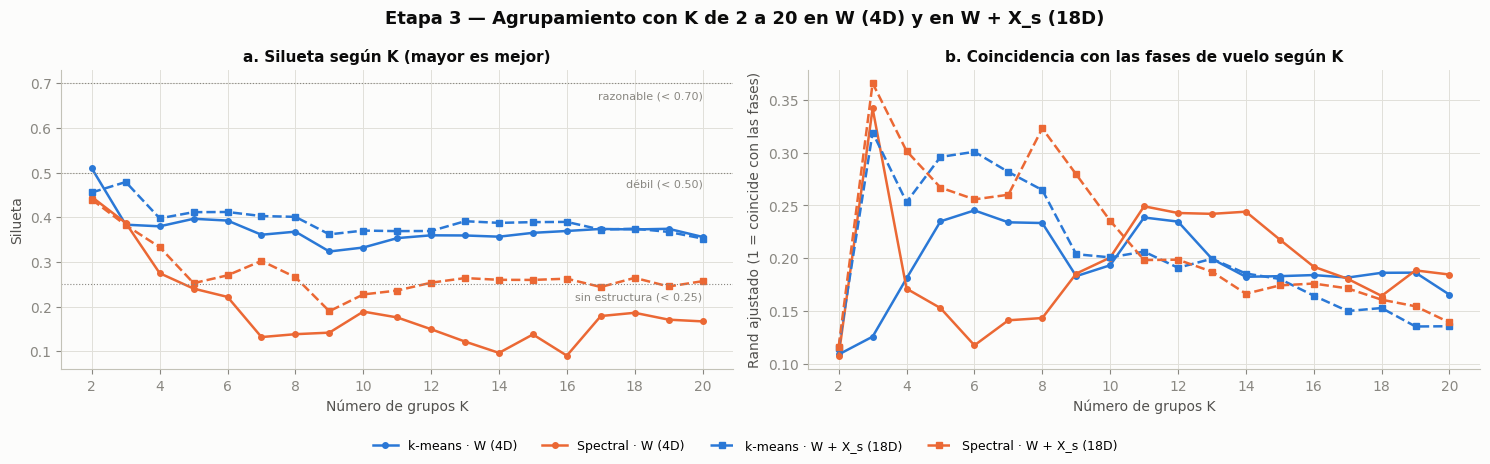

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
_METHOD_STYLE = {"k-means": dict(color="#2a78d6"), "Spectral": dict(color="#eb6834")}
_SPACE_STYLE = {"W (4D)": dict(ls="-", marker="o"), "W + X_s (18D)": dict(ls="--", marker="s")}
for ax, metric, title in ((axes[0], "Silueta", "a. Silueta según K (mayor es mejor)"),
                          (axes[1], "Rand ajustado vs. fases", "b. Coincidencia con las fases de vuelo según K")):
    for space in SPACES:
        for method in ("k-means", "Spectral"):
            sub = _km[(_km["Espacio"] == space) & (_km["Método"] == method)]
            ax.plot(sub["K"], sub[metric], lw=1.8, ms=4, label=f"{method} · {space}",
                    **_METHOD_STYLE[method], **_SPACE_STYLE[space])
    ax.set_title(title)
    ax.set_xlabel("Número de grupos K")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
axes[0].set_ylabel("Silueta")
axes[1].set_ylabel("Rand ajustado (1 = coincide con las fases)")
# Escala orientativa de Kaufman y Rousseeuw (1990) en el panel de la silueta
for lvl, txt in ((0.25, "sin estructura"), (0.50, "débil"), (0.70, "razonable")):
    axes[0].axhline(lvl, color=MUTED, lw=0.8, ls=":")
    axes[0].annotate(f"{txt} (< {lvl:.2f})", (K_RANGE[-1], lvl), xytext=(0, -11),
                     textcoords="offset points", ha="right", color=MUTED, fontsize=8)
# Una sola leyenda para toda la figura, debajo de los paneles, para no tapar la escala
_h, _l = axes[0].get_legend_handles_labels()
fig.legend(_h, _l, loc="lower center", ncol=4, fontsize=9)
fig.suptitle("Etapa 3 — Agrupamiento con K de 2 a 20 en W (4D) y en W + X_s (18D)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0.07, 1, 1))           # deja espacio abajo para la leyenda
fig.savefig(os.path.join(OUT_DIR, "etapa3_silueta_K.png"), dpi=160, bbox_inches="tight")
plt.show()

## 3.4 ¿Qué separan los grupos? Fases de vuelo, motores o estado de salud

Los sensores X_s responden a las condiciones de vuelo, pero también a la degradación del
motor. Por eso, al agrupar en 18D, los grupos podrían separar motores o etapas de la vida
útil en vez de regímenes de operación. Para la configuración elegida de cada método (la
de mayor silueta en k-means y Spectral; el codo en DBSCAN) se mide:

- **Rand ajustado frente a las fases:** cuánto coinciden los grupos con ascenso,
  nivelado y descenso.
- **Rand ajustado frente al motor:** cuánto coinciden con los 4 motores de
  entrenamiento. Un valor alto indica que el método separa motores, no regímenes.
- **η² del RUL:** fracción de la varianza del RUL que explican los grupos (de 0 a 1). Es
  cercana a 0 si en todos los grupos hay motores sanos y degradados en la misma
  proporción, y crece si los grupos separan etapas de la vida útil.

Como referencia se incluyen las propias fases de vuelo.

In [28]:
def eta_squared(y, lab):
    """Fracción de la varianza de y explicada por los grupos (sin el ruido de DBSCAN)."""
    m = lab >= 0
    y, lab = y[m], lab[m]
    mu = y.mean()
    # Varianza entre grupos: cuánto se alejan las medias de cada grupo de la media total
    between = sum((lab == c).sum() * (y[lab == c].mean() - mu) ** 2 for c in np.unique(lab))
    return float(between / np.sum((y - mu) ** 2))


_unit_sub, _rul_sub = dev["unit"][SUB], rul_dev[SUB]  # motor y RUL (recortado) de la submuestra
CHOSEN = {}                                           # configuración elegida por (espacio, método)
assoc_rows = [{"Espacio": "—", "Método": "Fases de vuelo (referencia)", "Parámetro": "umbral 10 pies/paso",
               "Grupos": 3, "Silueta": np.nan,
               "Rand ajustado vs. fases": 1.0,
               "Rand ajustado vs. motor": adjusted_rand_score(_unit_sub, phase_dev[SUB]),
               "η² del RUL": eta_squared(_rul_sub, phase_dev[SUB])}]
for space in SPACES:
    for method in ("k-means", "Spectral", "DBSCAN"):
        sub = cl_df[(cl_df["Espacio"] == space) & (cl_df["Método"] == method)]
        best = (sub[sub["_factor"] == 1.0].iloc[0] if method == "DBSCAN"
                else sub.sort_values("Silueta", ascending=False).iloc[0])
        CHOSEN[(space, method)] = best
        assoc_rows.append({"Espacio": space, "Método": method, "Parámetro": best["Parámetro"],
                           "Grupos": best["Grupos"], "Silueta": best["Silueta"],
                           "Rand ajustado vs. fases": best["Rand ajustado vs. fases"],
                           "Rand ajustado vs. motor": adjusted_rand_score(_unit_sub, best["_lab"]),
                           "η² del RUL": eta_squared(_rul_sub, best["_lab"])})
assoc_tab = pd.DataFrame(assoc_rows)
display(assoc_tab.round(3))

# Una partición extra para medir el límite de lo que puede hacer el espacio 18D: k-means
# con K = 20, el máximo probado. Si ni con 20 grupos aparece asociación con el RUL, los
# sensores no dominan el agrupamiento
_k20 = cl_df[(cl_df["Espacio"] == "W + X_s (18D)") & (cl_df["Método"] == "k-means")
             & (cl_df["K"] == K_RANGE[-1])].iloc[0]
print(f"\nk-means 18D con K = {K_RANGE[-1]}: Rand vs. fases {_k20['Rand ajustado vs. fases']:.3f} | "
      f"Rand vs. motor {adjusted_rand_score(_unit_sub, _k20['_lab']):.3f} | "
      f"η² del RUL {eta_squared(_rul_sub, _k20['_lab']):.3f}")

# Composición de los grupos: qué fracción de cada grupo es ascenso, nivelado o descenso, y
# la altitud y el TRA (posición del acelerador) medios, para el agrupamiento de mayor
# silueta de cada espacio
for space in SPACES:
    m_best = max(("k-means", "Spectral"), key=lambda m: CHOSEN[(space, m)]["Silueta"])
    lab = CHOSEN[(space, m_best)]["_lab"]
    comp = pd.crosstab(pd.Series([f"R{c + 1}" for c in lab], name="Grupo"),
                       pd.Series([PHASE_NAMES[p] for p in phase_dev[SUB]], name="Fase"),
                       normalize="index")[PHASE_NAMES] * 100
    comp["Altitud media (pies)"] = pd.Series(dev["features"][SUB, 0]).groupby(lab).mean().values
    comp["TRA medio (%)"] = pd.Series(dev["features"][SUB, 2]).groupby(lab).mean().values
    print(f"\n{space}, {m_best} {CHOSEN[(space, m_best)]['Parámetro']}: % de cada fase dentro de cada grupo")
    display(comp.round(1))

# Referencia: altitud y TRA medios de cada fase de vuelo
_ph = pd.DataFrame({"Fase": [PHASE_NAMES[p] for p in phase_dev[SUB]],
                    "Altitud media (pies)": dev["features"][SUB, 0],
                    "TRA medio (%)": dev["features"][SUB, 2]})
print("\nReferencia: altitud y TRA medios de cada fase de vuelo")
display(_ph.groupby("Fase")[["Altitud media (pies)", "TRA medio (%)"]].mean().loc[PHASE_NAMES].round(1))

,Espacio,Método,Parámetro,Grupos,Silueta,Rand ajustado vs. fases,Rand ajustado vs. motor,η² del RUL
0,—,Fases de vuelo (referencia),umbral 10 pies/paso,3,NaN,1.000,0.000,0.000
1,W (4D),k-means,K = 2,2,0.509,0.109,0.000,0.002
2,W (4D),Spectral,K = 2,2,0.445,0.108,0.000,0.002
3,W (4D),DBSCAN,eps = 0.267 (1 × codo),18,-0.479,0.006,0.002,0.010
4,W + X_s (18D),k-means,K = 3,3,0.479,0.319,0.000,0.002
5,W + X_s (18D),Spectral,K = 2,2,0.440,0.117,0.000,0.002
6,W + X_s (18D),DBSCAN,eps = 1.019 (1 × codo),1,NaN,0.018,0.002,0.000



k-means 18D con K = 20: Rand vs. fases 0.136 | Rand vs. motor 0.002 | η² del RUL 0.012

W (4D), k-means K = 2: % de cada fase dentro de cada grupo


Fase,Ascenso,Nivelado,Descenso,Altitud media (pies),TRA medio (%)
Grupo,,,,,
R1,28.8,59.1,12.1,26235.699219,74.800003
R2,31.8,27.9,40.3,15255.200195,58.400002



W + X_s (18D), k-means K = 3: % de cada fase dentro de cada grupo


Fase,Ascenso,Nivelado,Descenso,Altitud media (pies),TRA medio (%)
Grupo,,,,,
R1,22.8,68.3,8.9,26708.099609,75.300003
R2,65.5,29.9,4.7,15606.000000,71.900002
R3,0.0,10.1,89.9,17373.199219,43.599998



Referencia: altitud y TRA medios de cada fase de vuelo


,Altitud media (pies),TRA medio (%)
Fase,,
Ascenso,20483.699219,79.699997
Nivelado,24302.300781,71.400002
Descenso,19117.599609,47.599998


### Figura: los agrupamientos elegidos en cada espacio

Fila superior: el plano Mach–altitud, el mismo de la figura de v03. Fila inferior: las
dos primeras componentes principales de cada espacio, que muestran los datos desde el
ángulo en que más varían. En cada columna, el método de mayor silueta de ese espacio.

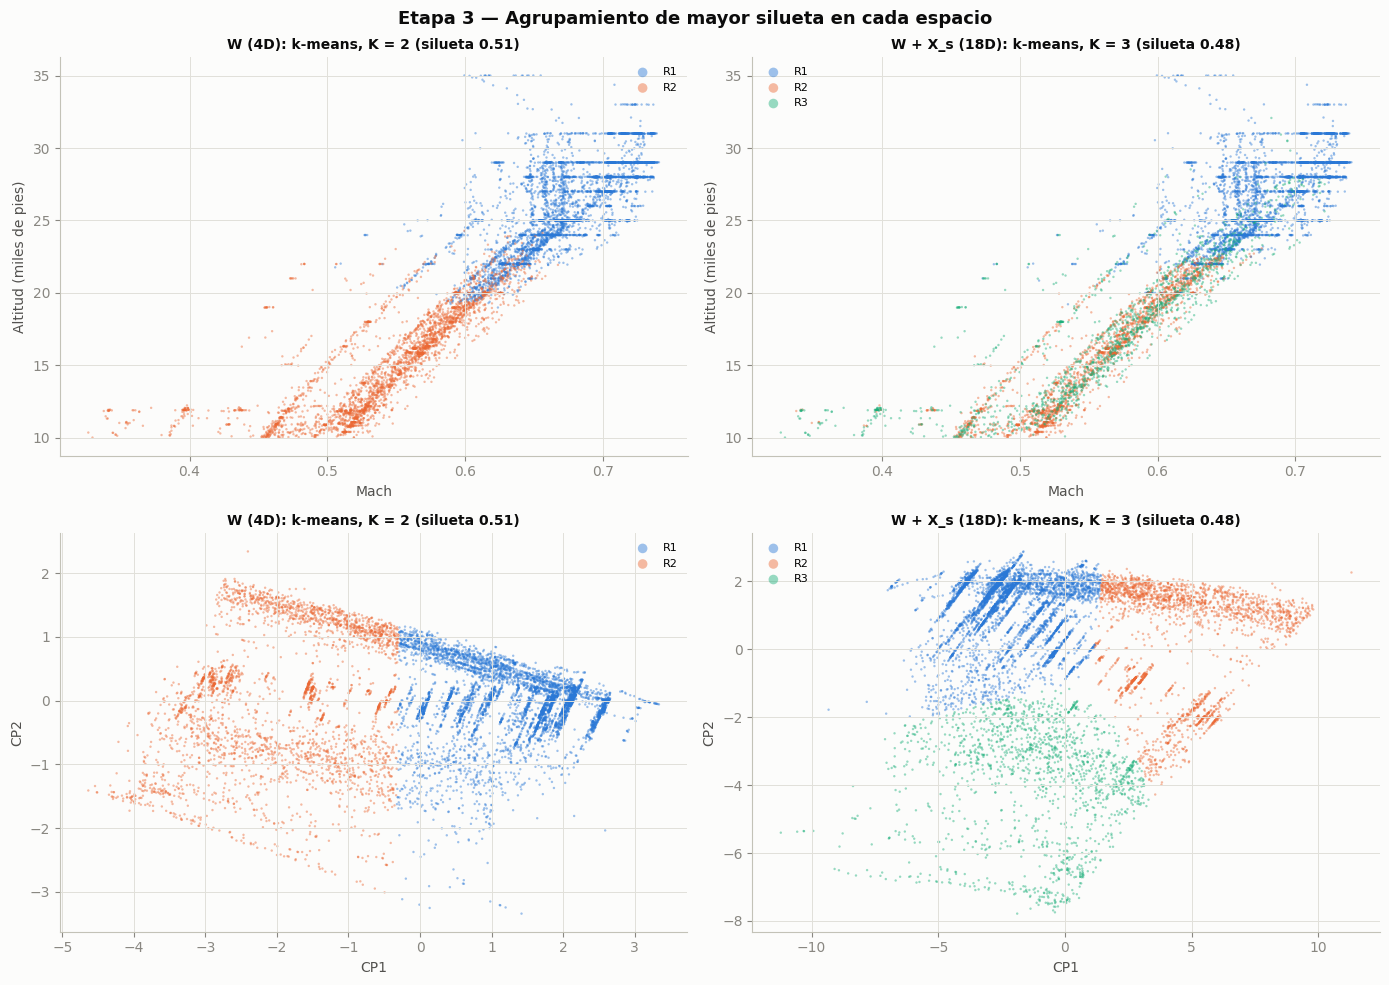

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for col, space in enumerate(SPACES):
    # Método de mayor silueta en este espacio (entre k-means y Spectral)
    m_best = max(("k-means", "Spectral"), key=lambda m: CHOSEN[(space, m)]["Silueta"])
    best = CHOSEN[(space, m_best)]
    lab = best["_lab"]
    # Proyección sobre las dos primeras componentes principales de este espacio
    pcs = PCA(n_components=2).fit(Z_DEV[space][_tr]).transform(XS[space])
    for row, (xv, yv, xl, yl) in enumerate((
            (dev["features"][SUB, 1], dev["features"][SUB, 0] / 1000, "Mach", "Altitud (miles de pies)"),
            (pcs[:, 0], pcs[:, 1], "CP1", "CP2"))):
        ax = axes[row, col]
        for c in np.unique(lab):
            mm = lab == c
            ax.scatter(xv[mm], yv[mm], s=3, alpha=0.45, edgecolor="none",
                       color=_CL_COLORS[c % len(_CL_COLORS)], label=f"R{c + 1}")
        ax.set_xlabel(xl)
        ax.set_ylabel(yl)
        ax.set_title(f"{space}: {m_best}, {best['Parámetro']} (silueta {best['Silueta']:.2f})",
                     fontsize=10)
        if best["Grupos"] <= 8:
            ax.legend(loc="best", fontsize=8, markerscale=4)
fig.suptitle("Etapa 3 — Agrupamiento de mayor silueta en cada espacio",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa3_espacios.png"), dpi=150, bbox_inches="tight")
plt.show()

## 3.5 Error por régimen

Regla registrada en la sección 0.12: el error por régimen usa el agrupamiento de mayor
silueta, como en v03. Los regímenes de operación se definen sobre W (el espacio de las
condiciones de vuelo); el espacio 18D es un diagnóstico y su silueta no es comparable
con la de W, porque las distancias se miden en otro número de dimensiones. Por eso la
regla se aplica dentro de W, con K de 2 a 20.

Si el agrupamiento elegido coincide con el de v03 (k-means, K = 2), el error por régimen
es el mismo que se informó en v03. En todo caso se recalcula aquí para la configuración
final y la base, **solo en validación** (motores 18 y 20): en v04 el conjunto de prueba
no se consulta salvo en la etapa 2.

In [30]:
_w_rows = cl_df[(cl_df["Espacio"] == "W (4D)") & (cl_df["Método"] != "DBSCAN")]
REGIME_BEST = _w_rows.sort_values("Silueta", ascending=False).iloc[0]
SAME_AS_V03 = REGIME_BEST["Método"] == "k-means" and REGIME_BEST.get("K") == 2
print(f"Agrupamiento de mayor silueta en W: {REGIME_BEST['Método']}, {REGIME_BEST['Parámetro']} "
      f"(silueta {REGIME_BEST['Silueta']:.3f})")
print("Coincide con el de v03 (k-means, K = 2)." if SAME_AS_V03 else "Distinto del de v03.")

RUN_REGIME_ERROR = not SMOKE_TEST   # en la prueba rápida las ventanas están submuestreadas


def window_labels(rec_labels, source, units=None):
    """Etiqueta de cada ventana = la más frecuente entre sus 30 registros (mismo orden que _gather)."""
    starts, w_unit, _ = WINDOWS[source]
    m = np.ones(len(starts), bool) if units is None else np.isin(w_unit, units)
    L = rec_labels[starts[m][:, None] + np.arange(WINDOW_SIZE)[None, :]]       # (N, 30)
    counts = np.stack([(L == c).sum(axis=1) for c in range(int(rec_labels.max()) + 1)], axis=1)
    return counts.argmax(axis=1)


def group_errors(preds, y, groups, names):
    """Tabla de error por grupo: % de ventanas, RMSE, sesgo y RMSE en la zona final."""
    rows = []
    for g, name in enumerate(names):
        m = groups == g
        if not m.any():
            continue
        fin = m & (y <= FINAL_ZONE)
        rows.append({
            "Grupo": name, "% ventanas": round(100 * m.mean(), 1),
            "RMSE": med_range([rmse(y[m], p[m]) for p in preds]),
            "Sesgo": med_range([np.mean(p[m] - y[m]) for p in preds]),
            "RMSE final": med_range([rmse(y[fin], p[fin]) for p in preds]) if fin.any() else "—",
        })
    return pd.DataFrame(rows)


if RUN_REGIME_ERROR:
    # Cada registro de dev recibe el grupo mayoritario entre sus 15 vecinos de la submuestra
    knn = KNeighborsClassifier(n_neighbors=KNN_ASSIGN).fit(XS["W (4D)"], REGIME_BEST["_lab"])
    regime_dev = knn.predict(Z_DEV["W (4D)"])
    regime_names = [f"R{c + 1}" for c in range(int(regime_dev.max()) + 1)]
    _, y_val, _ = build_tensors("global", "oficial")["val"]
    groups_val = window_labels(regime_dev, "dev", VAL_UNITS)     # régimen de cada ventana
    for cfg, (arch, alpha) in (("Final v03 (A6, α = 2)", (FINAL_V03["arch"], FINAL_V03["alpha"])),
                               ("Base (A3, MSE)", (BASE_ARCH, 1.0))):
        preds = [r["val_pred"] for r in reference if r["arch"] == arch and r["alpha"] == alpha]
        print(f"\n{cfg} · validación, por régimen")
        display(group_errors(preds, y_val, groups_val, regime_names))

Agrupamiento de mayor silueta en W: k-means, K = 2 (silueta 0.509)
Coincide con el de v03 (k-means, K = 2).



Final v03 (A6, α = 2) · validación, por régimen


,Grupo,% ventanas,RMSE,Sesgo,RMSE final
0,R1,63.7,4.18 [4.13 – 4.29],-0.61 [-1.29 – 0.43],1.59 [1.34 – 1.94]
1,R2,36.3,5.12 [4.83 – 5.73],-1.34 [-2.26 – -0.29],2.25 [1.82 – 2.80]



Base (A3, MSE) · validación, por régimen


,Grupo,% ventanas,RMSE,Sesgo,RMSE final
0,R1,63.7,4.64 [4.50 – 5.29],1.56 [1.18 – 2.69],2.34 [2.11 – 2.74]
1,R2,36.3,4.99 [4.56 – 5.81],0.38 [-0.09 – 2.52],2.65 [2.34 – 3.48]


## 3.6 Discusión

### ¿El clustering usaba 4 dimensiones o 2?

Usaba las 4 variables de W: la matriz de entrada tiene forma `(8000, 4)`, y el
agrupamiento con solo altitud y Mach no es igual al de las 4 variables (Rand ajustado
0,80; el 5 % de los registros cambia de grupo). Pero la impresión del profesor tiene una
causa real: **en la práctica, el agrupamiento en W queda dominado por una sola
dirección, la de la altitud.**

- Altitud, Mach y T2 están muy correlacionadas (|r| entre 0,84 y 0,98). T2, la
  temperatura a la entrada del ventilador, depende de la temperatura del aire, que cae con
  la altitud, y del Mach. Es casi una función de las otras dos: la cuarta componente
  principal explica 0,0 % de la varianza.
- La primera componente principal, una mezcla de altitud, Mach y T2, explica el 79 % de la
  varianza; con la segunda, que es casi solo TRA, se llega al 96 %.
- Como tres de las cuatro variables estandarizadas repiten la misma información, la
  misma información entra casi tres veces en la distancia euclidiana (como altitud, Mach y
  T2), y TRA solo una. k-means con K = 2 corta los datos por altitud: un grupo a unos
  26.000 pies y otro a unos 15.000.

Las proyecciones por pares muestran además **qué variable separa las fases de vuelo:
TRA**, la posición del acelerador. En el ascenso el acelerador está casi al máximo (TRA
medio 80 %), en el descenso está reducido (48 %) y en vuelo nivelado queda entre ambos
(71 %). En cambio, las tres fases recorren el mismo rango de altitudes. Un agrupamiento
dominado por la altitud no puede recuperar las fases, y eso explica el Rand ajustado bajo
de v03 (0,11).

### ¿Más grupos mejoran la silueta?

No. Ningún método supera la silueta que obtiene con K = 2 o 3:

| Espacio | Método | Mejor silueta (K) | Silueta con K de 4 a 20 |
|---|---|---|---|
| W (4D) | k-means | 0,51 (K = 2) | 0,32 a 0,40 |
| W (4D) | Spectral | 0,45 (K = 2) | 0,09 a 0,28 |
| W + X_s (18D) | k-means | 0,48 (K = 3) | 0,35 a 0,41 |
| W + X_s (18D) | Spectral | 0,44 (K = 2) | 0,19 a 0,33 |

Con la escala de Kaufman y Rousseeuw (1990), todos los valores indican una estructura
**débil**: salvo k-means con K = 2 en W (0,51, justo en el límite con "razonable"), ninguno
pasa de 0,50. Esto no es un error de ajuste. Los datos no forman nubes separadas, sino un
**continuo**: cada vuelo recorre de forma gradual todas las altitudes y velocidades entre
el despegue y el aterrizaje. Al cortar un continuo, los puntos de cada lado de un corte
quedan muy cerca del grupo vecino, y la silueta castiga justamente eso; con más grupos hay
más cortes y más puntos en esa situación. Spectral Clustering cae más que k-means porque
no busca grupos compactos, sino cortar el grafo de vecinos donde las conexiones son
débiles, y sus grupos pueden ser alargados; la silueta, que mide compacidad con distancias
euclidianas, los evalúa peor.

Los 18 grupos de DBSCAN en W tienen silueta negativa por la misma razón: DBSCAN separa
las zonas de mayor densidad del continuo, que probablemente corresponden a los tramos de
vuelo nivelado a altitud fija (las líneas horizontales en las proyecciones); no se
verificó grupo por grupo. En 18D, con `eps` en el codo, DBSCAN
junta todo en un solo grupo.

### Agrupar en 18 dimensiones

El espacio de 18 variables **se acerca más a las fases de vuelo**: k-means con K = 3 tiene
casi la misma silueta que el mejor agrupamiento en W (0,48 frente a 0,51) y un Rand
ajustado de 0,32 frente a 0,11. Uno de sus grupos es en un 90 % descenso (TRA medio 44 %),
otro es en un 66 % ascenso a baja altitud y el tercero es en un 68 % vuelo nivelado a gran
altitud. La explicación es que varios sensores (flujo de combustible, velocidades de los
ejes, temperaturas y presiones internas) responden a la posición del acelerador, de modo
que en 18D el TRA pesa más en la distancia.

La precaución del plan no se confirmó: **los grupos en 18D no separan motores ni estados
de salud**. El Rand ajustado frente al motor es 0,00 y el η² del RUL es 0,002; ni con 20
grupos pasa de 0,012. En los sensores, la variación por condiciones de vuelo es mucho
mayor que la variación por degradación, y por eso domina el agrupamiento.

### Error por régimen

El agrupamiento de mayor silueta en W sigue siendo k-means con K = 2, el mismo de v03, de
modo que el error por régimen es el que ya se informó: la configuración final se equivoca
más en el régimen de baja altitud (RMSE final 2,25 frente a 1,59 en validación). Con lo
visto en esta etapa, ese régimen debe leerse como "vuelo a baja altitud", no como una fase
de vuelo.

### Conclusiones

1. El clustering de v03 sí usaba las 4 variables de W, pero tres de ellas son
   prácticamente redundantes. El resultado se comporta como un corte por altitud.
2. Aumentar el número de grupos no mejora la silueta, porque los datos de operación forman
   un continuo y no grupos separados.
3. Las fases de vuelo se distinguen por la posición del acelerador. Un agrupamiento que
   incluya los sensores del motor las aproxima mejor (Rand ajustado 0,32), sin mezclarse
   con el estado de salud. Aun así, las fases definidas por la tasa de ascenso siguen
   siendo la referencia más clara para analizar el error por régimen.

**Limitaciones.** La silueta y el Rand ajustado se calculan sobre una submuestra de 8.000
registros de entrenamiento. No se probaron otras formas de pesar las variables (por
ejemplo, eliminar T2 o pesar TRA) porque cambiarían la pregunta del profesor; quedan como
trabajo posible.

**Referencia:** Kaufman, L. y Rousseeuw, P. J. (1990). *Finding Groups in Data: An
Introduction to Cluster Analysis*. Wiley.

# Etapa 4 — Documentación

Esta etapa no tiene código. Los documentos de v04 están en la carpeta del proyecto:

| Archivo | Contenido |
|---|---|
| `Plan_ProjectV04.md` | Plan por etapas, decisiones y estado |
| `Diagramas.md` | Pipeline, A6 con y sin pooling con la forma de cada tensor, decisión del pooling y análisis de regímenes (Mermaid) |
| `Guia_Estudio.md` | La guía de v03 más el pooling (sección 2.4) y el agrupamiento de regímenes (sección 9) |
| `Preparacion_Defensa.md` | Preguntas probables, con las nuevas sobre pooling y clustering |
| `Metodologia_IA.md` | Metodología de uso de IA, con las decisiones, salvaguardas y errores de v04 |

## Resumen de v04: respuesta a los pedidos de la Reunión 05

| Pedido | Respuesta |
|---|---|
| ¿Por qué no hay una capa de pooling? | Decisión heredada de Li, Ding y Sun (2018), que la desaconsejan con ventanas de 30 pasos. El experimento la respalda: con α = 2, el pooling empeora el RMSE final en validación (1,83 a 2,03) y la regla pre-registrada no lo adopta |
| Clustering con más grupos para mejorar la silueta | Con K de 2 a 20, ningún método mejora su silueta de K = 2 o 3: los datos de operación forman un continuo, no grupos separados |
| ¿El clustering usa todas las dimensiones o solo dos? | Usa las 4 de W, pero altitud, Mach y T2 repiten la misma información, y el resultado es un corte por altitud. Las fases se distinguen por TRA. Con las 18 variables del modelo, los grupos se acercan más a las fases sin mezclarse con el estado de salud |
| Subir el proyecto a GitHub | Repositorio `github.com/matii-gr/Memoria_RUL` |

**Configuración final:** sin cambios respecto de v03 (A6 + normalización global + α = 2).
El conjunto de prueba no se volvió a usar en v04.